# 👁️ Foveated Diffusion Through a Neuroscience Lens
### *Biologically-Inspired Generative Vision*
> **intro to NeuroAI Final Project** | Roi Maman & Roy Carmel | 2026
 
---

# 🔵1) intro

Biological vision spends its resolution unevenly: peak acuity is restricted to the fovea, and resolution falls off quickly towards the periphery. The paper "Foveated Diffusion: Efficient Spatially Adaptive Image and Video Generation" (Chao, Yariv, Xiao, Wetzstein) applies the same idea to diffusion transformers: tokens stay at full resolution only inside a foveation mask and are merged to a lower resolution elsewhere, which shortens the token sequence and the generation time.

In the paper the mask comes from outside the model: random circles during training, and a gaze point, a saliency map or a bounding box at inference. We ask whether a simple model of early visual processing can choose the fovea instead. A bank of Gabor filters, the classic model of V1 simple-cell receptive fields, measures oriented edge and texture energy, and the high-energy regions become the fovea.

The notebook reproduces the paper's pipeline on PixArt-α (sections 3-5), trains a LoRA whose fovea follows each training image's Gabor energy (section 6), and compares the trained models side by side (section 7).

# 🔵2) background: the paper's method, and what we change

The paper makes a pretrained diffusion transformer (DiT) generate with fewer tokens:
1. **Foveated tokenization.** Given a binary mask $M$ on the token grid, tokens inside the fovea stay at full resolution; outside it, one token represents a 2×2 block of tokens. With $m$ fovea tokens out of $h \cdot w$, the sequence length is $L = m + (h \cdot w - m)/4$.
2. **Naive mixed-resolution denoising** (no training) fails: the low- and high-resolution regions disagree in scale and structure, producing duplicated or fused objects (paper Fig. 4).
3. **Foveated training.** LoRA post-training on foveated targets built from real images: fine tokens from the image latent $E(x)$, coarse tokens from the latent of the downsampled image $E(\mathrm{Down}(x))$, merged by the mask (paper Fig. 2b). Random masks during training let the model handle any fovea position at inference.
4. **Decoding.** The two token sets are decoded separately by the VAE, the periphery is upsampled, and the two images are blended with the mask (paper Eqs. 5-7).

With about 25% of the tokens the paper reports more than 2× faster image generation (FLUX.2 Klein 4B) and more than 4× faster video generation (Wan2.1 1.3B), and a user study finds the foveated images close to indistinguishable from full resolution.

**What we change:**
- **Model:** PixArt-α 512 (a 0.6B DiT) instead of FLUX, so it trains on a single GPU.
- **Positions:** PixArt adds absolute sin-cos positions once at the input, so coarse tokens get the sin-cos position of the centre of the block they replace, instead of the paper's phase-aligned RoPE.
- **Objective:** PixArt's own noise-prediction (DDPM) loss instead of flow matching.
- **Data:** DiffusionDB images.
- **Masks (our extension):** the fovea is placed by Gabor energy instead of random circles (section 6).

# 🔵3) implementing the base denoising loop using PixArt-Alpha

### Baseline Implementation: Manual PixArt-α Denoising Loop

Before introducing foveation, we build a transparent full-resolution baseline. High-level interfaces such as Hugging Face's `DiffusionPipeline` hide the token projections and tensor layouts, so we write the denoising loop by hand to get access to them.

#### Model Selection: Why PixArt-α?
* **A transformer backbone is needed.** Stable Diffusion (v1.5 / v2 / SDXL) uses a convolutional U-Net, which needs a dense, regular $C \times H \times W$ grid; a mixed-resolution token set does not form one. A Diffusion Transformer (DiT) patchifies the latent into a sequence of tokens, and its attention and MLP layers accept a sequence of any length, so tokens can be merged in the periphery. Attention cost grows quadratically with the number of tokens and the MLPs linearly, so fewer tokens means less compute.
* **PixArt-α instead of FLUX.** The paper fine-tunes FLUX.2 Klein 4B for images (and Wan2.1 1.3B for video) on 8 H100 GPUs. PixArt-α (~0.6B parameters) keeps the same ingredients that matter here - a DiT over latent tokens with T5 text conditioning - and LoRA training fits on a single GPU.

#### Objectives of this Baseline
1. **Reference images and timing** at full sequence length (100% of the tokens), for comparison with the foveated runs.
2. **Access to every component** the foveated version replaces or reuses: T5 text conditioning, adaptive layer-norm (adaLN) timestep conditioning, classifier-free guidance (CFG), the DPM-Solver multistep scheduler, and VAE decoding.

### 🟠3.1) encoding the prompt with T5, then freeing T5 from memory

#### Why Decouple Text Encoding? (VRAM)

PixArt-α uses the encoder of **T5-v1.1-XXL** as its text encoder: about 4.8B parameters, ~19 GB in fp32 and ~9.6 GB in fp16. Keeping it on the GPU next to the transformer and the VAE leaves little room on a consumer GPU.

So the text is encoded once, up front:
* **Pre-computation:** the prompt and the empty negative prompt go through T5 once, giving the embeddings (`prompt_embeds`) and attention masks (`prompt_attention_mask`), ordered [negative, prompt] for CFG.
* **Freeing T5:** the T5 model and tokenizer are deleted.

In [2]:
import os
os.environ["_CHECK_PEFT"] = "0"


import torch
import PIL
import numpy as np
import gc
from tqdm.auto import tqdm
from diffusers import PixArtAlphaPipeline, Transformer2DModel, AutoencoderKL
from transformers import T5EncoderModel
from IPython.display import display

print("Loading T5 Text Encoder temporarily...")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# Load only the encoder to memory
text_encoder = T5EncoderModel.from_pretrained(
    model_id, 
    subfolder="text_encoder", 
    torch_dtype=torch.float16
).to("cuda")

# Load its tokenizer
from transformers import T5Tokenizer
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")

prompt = "a small dog with a mexican hat"
negative_prompt = ""

device = torch.device("cuda")
max_sequence_length = 120  # PixArt's prompt length

def encode_text(prompt, negative_prompt):
    text_inputs = tokenizer(
        prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    text_input_ids = text_inputs.input_ids.to(device)
    prompt_attention_mask = text_inputs.attention_mask.to(device)
    prompt_embeds = text_encoder(text_input_ids, attention_mask=prompt_attention_mask)[0]

    uncond_inputs = tokenizer(
        negative_prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    uncond_input_ids = uncond_inputs.input_ids.to(device)
    negative_attention_mask = uncond_inputs.attention_mask.to(device)
    negative_prompt_embeds = text_encoder(uncond_input_ids, attention_mask=negative_attention_mask)[0]

    return prompt_embeds, prompt_attention_mask, negative_prompt_embeds, negative_attention_mask

print("Encoding prompt...")
with torch.no_grad():
    p_embeds, p_mask, n_embeds, n_mask = encode_text(prompt, negative_prompt)

# [negative, positive]: the order the CFG chunk(2) expects
prompt_embeds = torch.cat([n_embeds, p_embeds], dim=0)
prompt_attention_mask = torch.cat([n_mask, p_mask], dim=0)

# free T5 before the transformer is loaded
print("Unloading T5 from VRAM...")
del text_encoder
del tokenizer
torch.cuda.empty_cache()
gc.collect()
print(f"VRAM after clearing T5: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading T5 Text Encoder temporarily...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompt...
Unloading T5 from VRAM...
VRAM after clearing T5: 0.01 GB


### 🟠3.2) loading the transformer and VAE, and running the denoising loop on the pre-computed embeddings

#### Manual Diffusion Inference on Pre-computed Embeddings

With T5 gone, we load the transformer (`Transformer2DModel`, a DiT) and the VAE (`AutoencoderKL`) and run the denoising loop:

1. **Initial noise:** standard Gaussian noise in the 4×64×64 latent space, scaled by the scheduler's `init_noise_sigma`.
2. **Classifier-free guidance (CFG):** at each timestep the latent is duplicated (`torch.cat([x] * 2)`) so the unconditional and conditional predictions come from one forward pass, and they are combined as
   $$\epsilon_\theta = \epsilon_{\text{uncond}} + s \cdot (\epsilon_{\text{text}} - \epsilon_{\text{uncond}})$$
3. **Scheduling:** PixArt-α predicts the noise $\epsilon$ , `DPMSolverMultistepScheduler` turns it into the next latent, over 20 steps.
4. **VAE decoding:** the final latent is divided by the VAE scaling factor and decoded to a 512×512 RGB image, the full-resolution reference.

Loading Transformer and VAE to GPU...


Some weights of the model checkpoint were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


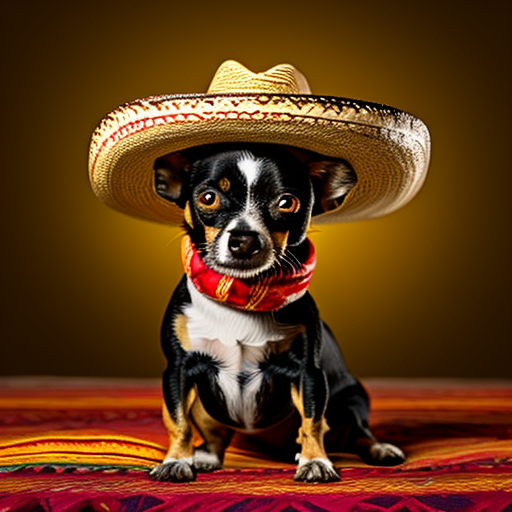

In [3]:
print("Loading Transformer and VAE to GPU...")
transformer = Transformer2DModel.from_pretrained(
    model_id, 
    subfolder="transformer", 
    torch_dtype=torch.float16
).to("cuda")

vae = AutoencoderKL.from_pretrained(
    model_id, 
    subfolder="vae", 
    torch_dtype=torch.float16
).to("cuda")

# standard PixArt scheduler
from diffusers import DPMSolverMultistepScheduler
scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")


# manual denoising loop
def run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5, height=512, width=512):
    generator = torch.Generator(device=device).manual_seed(seed)
    
    scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    latents = latents * scheduler.init_noise_sigma

    resolution = torch.tensor([height, width], dtype=torch.float16, device=device).repeat(2, 1)
    aspect_ratio = torch.tensor([float(height / width)], dtype=torch.float16, device=device).repeat(2, 1)
    added_cond_kwargs = {"resolution": resolution, "aspect_ratio": aspect_ratio}

    print("Running Denoising Loop on GPU...")
    for i, t in enumerate(tqdm(scheduler.timesteps)):
        latent_model_input = torch.cat([latents] * 2)
        
        t = t.to(device)
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        t_val = t.item() if isinstance(t, torch.Tensor) else t
        t_batch = torch.tensor([t_val, t_val], device=device)

        with torch.no_grad():
            noise_pred = transformer(
                latent_model_input,
                encoder_hidden_states=prompt_embeds,
                encoder_attention_mask=prompt_attention_mask,
                timestep=t_batch,
                added_cond_kwargs=added_cond_kwargs,
                return_dict=False,
            )[0]

        if noise_pred.shape[1] == 8:
            noise_pred, _ = noise_pred.chunk(2, dim=1)

        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        latents = scheduler.step(noise_pred, t, latents).prev_sample
        latents = latents.to(device)

    # decode the final latents with the VAE
    print("Decoding latents to image...")
    with torch.no_grad():
        latents = (1 / vae.config.scaling_factor) * latents
        image = vae.decode(latents.to(vae.dtype)).sample

    # transform the decoded image to a PIL image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

image = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=7.5)
display(image)

# 🔵4) Naïve foveated diffusion (training-free mixed-resolution baseline)

The paper's *naive mixed-resolution denoising* baseline: the pretrained PixArt denoises a mixed-resolution token sequence, with no training.
- inside the foveation mask: normal high-res tokens (each covers 16x16 pixels)
- outside it: one low-res token per 2x2 block of high-res tokens (covers 32x32 pixels), so 4x fewer tokens in the periphery. The mask is kept at token resolution: a block that is only partly inside the fovea keeps its fovea tokens and also gets a low-res token for the rest
- the transformer blocks accept any token sequence; only the patch embedding, the positional embeddings and the unpatchify assume a grid, so we redo those per token. Low-res tokens get PixArt's sin-cos position at the centre of the block they replace (our stand-in for the paper's phase-aligned RoPE)
- at the end the two parts are decoded separately by the VAE, the periphery is upsampled and the two are blended (Eq. 5-7)

The paper's naive baseline shows scale mismatches and duplicated objects at the boundary (its Fig. 4-5). Ours fails differently: the fovea is fine and the scene layout carries across the boundary, but the periphery comes out as saturated, blocky texture. PixArt has never seen tokens that sit 2 positions apart and cover 4x the area, and it adds positions only once, at the input. Sections 5-6 fix this with training; Appendix A tests whether classifier-free guidance amplifies the failure.

Uses `transformer`, `vae`, `scheduler`, `prompt_embeds`, `prompt_attention_mask`, `device` and `run_diffusion_loop` from section 3 - run 3.1 and 3.2 first.

### 🟠4.1) foveated tokenization: masks, packing and positions

In [4]:
import time
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

P = transformer.config.patch_size      # 2 -> one token = 2x2 latent pixels 
C = transformer.config.in_channels     # 4 latent channels
D = transformer.inner_dim              # 1152 hidden size
pe = transformer.pos_embed
POS_SCALE = pe.base_size / pe.height / pe.interpolation_scale   # PixArt's position scaling (=1 for the 512 model)
GRID = pe.height                       # the high-res token grid is GRID x GRID (32x32 for 512x512 images)

def patchify(z):
    """(B, C, H, W) latent grid -> (B, H/P * W/P, P*P*C) tokens, row-major, same layout PixArt uses to unpatchify."""
    B, c, H, W = z.shape
    return z.reshape(B, c, H // P, P, W // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, (H // P) * (W // P), P * P * c)

def unpatchify(tokens, h, w, c=C):
    """(B, h*w, P*P*c) tokens -> (B, c, h*P, w*P) latent grid."""
    B = tokens.shape[0]
    return tokens.reshape(B, h, w, P, P, c).permute(0, 5, 1, 3, 2, 4).reshape(B, c, h * P, w * P)

def make_circular_mask(center=(0.5, 0.5), radius=0.25, grid=GRID):
    """Circular foveation mask on the high-res token grid. center=(y, x) and radius are fractions of the image size."""
    ys, xs = torch.meshgrid(torch.arange(grid), torch.arange(grid), indexing="ij")
    ys, xs = (ys + 0.5) / grid, (xs + 0.5) / grid
    return (ys - center[0]) ** 2 + (xs - center[1]) ** 2 < radius ** 2

def build_layout(M):
    """
    Foveated token layout from a boolean mask M on the high-res token grid (h x w), kept at token resolution.
    Every fovea token stays high-res; every 2x2 block that is not entirely fovea gets one low-res token,
    so a block that is only partly fovea carries both (its fovea tokens + a coarse token for the rest).
    Sequence order: [high-res tokens (row-major) | low-res tokens (row-major)].
    """
    h, w = M.shape
    Mb = M.reshape(h // 2, 2, w // 2, 2).all(dim=3).all(dim=1)     # block grid: True = block is entirely fovea
    hi_idx = M.flatten().nonzero().squeeze(1)
    lo_idx = (~Mb).flatten().nonzero().squeeze(1)

    # token coordinates on the high-res token grid, in (x, y) order like PatchEmbed
    ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
    ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
    lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5   # centre of the 2x2 block it replaces
    xy = torch.cat([hi_xy, lo_xy]) * POS_SCALE

    # the same sin-cos embedding PixArt uses, just evaluated at our (possibly fractional) positions
    pos = get_2d_sincos_pos_embed_from_grid(D, xy.T.to(device), output_type="pt").float()[None]

    n_hi, n_lo = len(hi_idx), len(lo_idx)
    return dict(M=M, Mb=Mb, hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos,
                n_hi=n_hi, n_lo=n_lo, h=h, w=w, token_ratio=(n_hi + n_lo) / (h * w))

### 🟠4.2) PixArt forward pass on a foveated token sequence + sanity checks

In [5]:
@torch.no_grad()
def fov_transformer(x, t, layout, prompt_embeds, prompt_attention_mask, model=None):
    """
    PixArt forward pass on a packed foveated token sequence.
    x: (B, L, P*P*C) noisy latent patches -> returns the predicted noise, same shape.
    Same as transformer.forward(), except the steps that assume a regular grid
    (patch embedding, positions, unpatchify) are done per token.
    model: the transformer to run, e.g. one with a merged LoRA. None = the base `transformer` of 3.2.
    """
    m = transformer if model is None else model
    dtype = m.pos_embed.proj.weight.dtype                 # inputs follow the model's dtype
    x, prompt_embeds = x.to(dtype), prompt_embeds.to(dtype)
    B = x.shape[0]

    # 1. patch embedding: PixArt's conv (kernel = stride = P) is just a linear layer applied to each patch
    W_in = m.pos_embed.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C)   # (p, q, c) order, matches patchify()
    h = (F.linear(x, W_in, m.pos_embed.proj.bias) + layout["pos"]).to(dtype)

    # 2. timestep + text conditioning, as in transformer.forward
    #    (resolution/aspect_ratio are ignored by the 512 model; the 1024 model needs real values here)
    t_emb, t_raw = m.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                  batch_size=B, hidden_dtype=h.dtype)
    enc = m.caption_projection(prompt_embeds).view(B, -1, D)
    enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

    # 3. transformer blocks - these don't care about the grid, any token sequence works
    for block in m.transformer_blocks:
        h = block(h, attention_mask=None, encoder_hidden_states=enc, encoder_attention_mask=enc_bias,
                  timestep=t_emb, cross_attention_kwargs=None, class_labels=None)

    # 4. output head, per token
    shift, scale = (m.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = m.norm_out(h) * (1 + scale) + shift
    out = m.proj_out(h)                                                    # (B, L, P*P*8)
    out = out.reshape(B, -1, P * P, m.out_channels)[..., :C]              # keep eps, drop the learned-variance channels
    return out.reshape(B, -1, P * P * C)

### 🟠4.3) foveated denoising loop and decoding
Same loop as 3.2, but the latent is a packed sequence of L patches instead of a 64x64 grid. The initial noise is taken from the same full-resolution noise 3.2 draws for a given seed (coarse tokens get the 2x2 average, times 2 to keep unit variance), so full-res and foveated runs of one seed are directly comparable.

`run_foveated_loop` and `decode_foveated` are the shared loop and decoder of the notebook: sections 6.2 and 7 call them with `model=` (a transformer with a merged LoRA) and `smooth=True` (Gaussian-blurred blend at the fovea border). `guidance_scale_lo` and `rescale_lo` are only used by Appendix A.

In [6]:
import torchvision.transforms.functional as TF

def to_pil(img):
    img = (img.float() / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
    return PIL.Image.fromarray((img * 255).round().astype("uint8"))

def foveated_noise(layout, seed):
    """
    Initial noise for the packed sequence, taken from the SAME full-res noise run_diffusion_loop draws for this seed,
    so full-res and foveated runs are directly comparable. Low-res noise = 2x2 average * 2 (keeps unit variance).
    """
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn((1, C, layout["h"] * P, layout["w"] * P), generator=g, device=device, dtype=torch.float16)
    z_lo = (F.avg_pool2d(z.float(), 2) * 2).half()
    return torch.cat([patchify(z)[:, layout["hi_idx"]], patchify(z_lo)[:, layout["lo_idx"]]], dim=1)

def run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=42, steps=20,
                      guidance_scale=4.5, guidance_scale_lo=None, rescale_lo=False, model=None):
    """
    The foveated denoising loop, shared by every section that generates (4, 6.2, 7, Appendix A).
    model             : the transformer to run, e.g. one with a merged LoRA. None = the base `transformer` of 3.2.
    guidance_scale_lo : separate CFG weight for the peripheral tokens. None = same as the fovea.
    rescale_lo        : renormalise the peripheral eps to the std of its own eps_text.
                        Removes CFG magnitude inflation without pushing the prompt differently on
                        the two sides of the seam, so it should not add a contrast step at the border.
    Latents are kept in fp32; the model runs in its own dtype.
    """
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed).float() * scheduler.init_noise_sigma   # (1, L, P*P*C) instead of (1, 4, 64, 64)
    n_hi = layout["n_hi"]

    # CFG is elementwise on the token axis, so the weight can just be a per-token vector
    g = torch.full((1, x.shape[1], 1), float(guidance_scale), device=device)
    if guidance_scale_lo is not None:
        g[:, n_hi:] = float(guidance_scale_lo)

    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_text = fov_transformer(x_in, t, layout, prompt_embeds, prompt_attention_mask,
                                               model=model).float().chunk(2)
        eps = eps_uncond + g * (eps_text - eps_uncond)
        if rescale_lo:
            s = eps_text[:, n_hi:].std() / (eps[:, n_hi:].std() + 1e-6)
            eps[:, n_hi:] = eps[:, n_hi:] * s
        x = scheduler.step(eps, t, x).prev_sample                     # scheduler math is elementwise, the shape doesn't matter
    return x

@torch.no_grad()
def decode_foveated(x, layout, smooth=False, smooth_kernel=11, smooth_sigma=3.0):
    """
    Split -> decode each part with the VAE -> upsample the periphery -> blend with the mask (paper Eq. 5-7).
    smooth=True blends with a Gaussian-blurred mask (default 11x11, sigma 3, as in 5.4) instead of a hard one.
    Returns PIL images: (blended, fine branch, coarse branch).
    """
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)          # (1,4,64,64) and (1,4,32,32)

    # fill each grid's empty part from the other one, so the VAE decoder doesn't see zeros next to the boundary
    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)
    z_hi = torch.where(m_hi, z_hi, F.interpolate(z_lo.float(), scale_factor=2, mode="nearest").to(z_hi.dtype))

    sf = vae.config.scaling_factor
    img_hi = vae.decode((z_hi / sf).to(vae.dtype)).sample                      # (1,3,512,512)
    img_lo = vae.decode((z_lo / sf).to(vae.dtype)).sample                      # (1,3,256,256)
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).to(device)
    if smooth:
        m_px = TF.gaussian_blur(m_px[None], kernel_size=[smooth_kernel] * 2, sigma=[smooth_sigma] * 2)[0]
    img = m_px * img_hi.float() + (1 - m_px) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

def draw_fovea_border(pil_img, layout, color=(255, 255, 255)):
    """White outline around the high-res region, like the figures in the paper."""
    m = F.interpolate(layout["M"].float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return PIL.Image.fromarray(arr)

### 🟠4.4) full high-res vs naive foveated (same prompt, same seed)
The cell prints the token ratio and the wall-clock time of each run. Both times include VAE decoding, and the foveated run decodes twice (fovea and periphery).

tokens: 208 high-res + 212 low-res = 420 / 1024  (token ratio 41%)
Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


  0%|          | 0/20 [00:00<?, ?it/s]

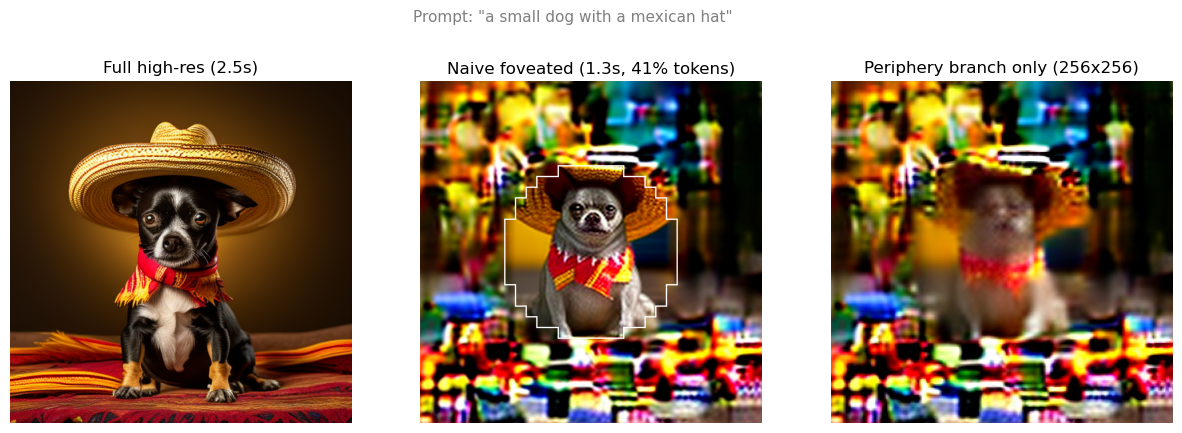

In [7]:
SEED, STEPS, GUIDANCE = 42, 20, 4.5

layout = build_layout(make_circular_mask(center=(0.5, 0.5), radius=0.25))
print(f"tokens: {layout['n_hi']} high-res + {layout['n_lo']} low-res = {layout['n_hi'] + layout['n_lo']} "
      f"/ {layout['h'] * layout['w']}  (token ratio {layout['token_ratio']:.0%})")

torch.cuda.synchronize(); t0 = time.time()
img_full = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask,
                              seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
torch.cuda.synchronize(); t_full = time.time() - t0

t0 = time.time()
x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
img_fov, img_hi, img_lo = decode_foveated(x, layout)
torch.cuda.synchronize(); t_fov = time.time() - t0

panels = [
    (img_full, f"Full high-res ({t_full:.1f}s)"),
    (draw_fovea_border(img_fov, layout), f"Naive foveated ({t_fov:.1f}s, {layout['token_ratio']:.0%} tokens)"),
    (img_lo, "Periphery branch only (256x256)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f'Prompt: "{prompt}"', fontsize=11, color="gray")
plt.show()

### 🟠4.5) different foveation patterns (same prompt and seed, like Fig. 9 in the paper)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

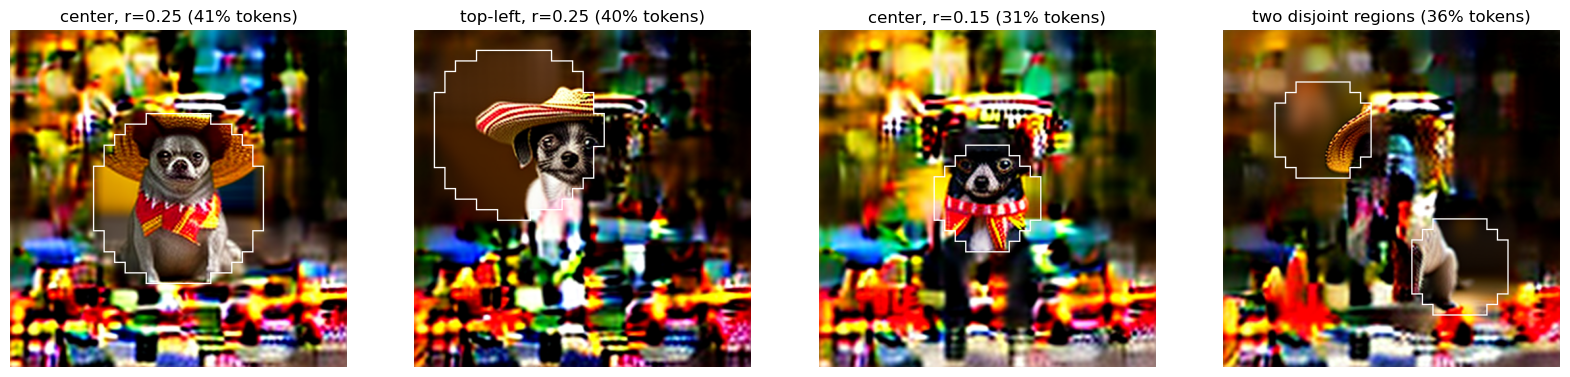

In [8]:
masks = {
    "center, r=0.25":       make_circular_mask((0.5, 0.5), 0.25),
    "top-left, r=0.25":     make_circular_mask((0.3, 0.3), 0.25),
    "center, r=0.15":       make_circular_mask((0.5, 0.5), 0.15),
    "two disjoint regions": make_circular_mask((0.3, 0.3), 0.15) | make_circular_mask((0.7, 0.7), 0.15),
}

fig, axes = plt.subplots(1, len(masks), figsize=(5 * len(masks), 5))
for ax, (name, M) in zip(axes, masks.items()):
    lay = build_layout(M)
    x = run_foveated_loop(lay, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
    img_fov, _, _ = decode_foveated(x, lay)
    ax.imshow(draw_fovea_border(img_fov, lay))
    ax.set_title(f"{name} ({lay['token_ratio']:.0%} tokens)")
    ax.axis("off")
plt.show()

# 🔵5) foveated training: LoRA with random circular foveae

### Why the naive baseline fails, and the fix

Section 4 showed that the pretrained model handles the fovea tokens but not the peripheral ones:
1. **Out-of-distribution tokens.** A peripheral token covers 4x the area of a normal token and sits at a block-centre position, between the grid positions PixArt was trained on. The model's noise prediction there is poor, so the periphery does not denoise to a clean latent, and classifier-free guidance can amplify the error (Appendix A).
2. **A visible seam.** The two regions are decoded separately and blended with a hard binary mask in `decode_foveated`, so any mismatch in scale, colour or contrast shows up at the fovea boundary.

#### The fix: foveated training with LoRA (paper Fig. 2b)
Instead of retraining the 600M-parameter DiT, we train **LoRA** adapters on its attention and MLP projections, on mixed-resolution token sequences built from real images: fine tokens from the image latent $E(x)$, coarse tokens from the latent of the 2x downsampled image $E(\mathrm{Down}(x))$, merged by the mask. Both parts are noised to the same timestep, each with its own noise, and the model learns to predict that noise (PixArt's own objective; the paper uses flow matching for FLUX).

#### LoRA (Hu et al., 2021)
For each adapted layer, the pretrained weight stays frozen and a small trainable low-rank update is added next to it:

$$h = W_0\,x + \frac{\alpha}{r}\,B\,A\,x$$

- $x \in \mathbb{R}^{d_{in}}$: the layer's input (a token's feature vector); $h \in \mathbb{R}^{d_{out}}$: its output.
- $W_0 \in \mathbb{R}^{d_{out} \times d_{in}}$: the pretrained PixArt weight, **frozen** (never updated).
- $A \in \mathbb{R}^{r \times d_{in}}$ and $B \in \mathbb{R}^{d_{out} \times r}$: the **only trained parameters**. $A$ projects the input down to $r$ dimensions, $B$ projects it back up, so the update $\Delta W = \frac{\alpha}{r} B A$ has rank at most $r$.
- $r$: the rank, here 32 - much smaller than $d_{in}, d_{out}$ (1152 or 4608 in PixArt), so each layer trains $r\,(d_{in} + d_{out})$ numbers instead of $d_{in} \cdot d_{out}$.
- $\alpha$: a fixed scaling constant, here 64, so the update is multiplied by $\alpha / r = 2$.

$B$ starts at zero, so at the first step $\Delta W = 0$ and the model is exactly the pretrained one (the naive baseline of section 4). After training, the update is merged into the weights, $W = W_0 + \frac{\alpha}{r} B A$, so inference costs nothing extra. We apply it to the attention projections (`to_q`, `to_k`, `to_v`, `to_out.0`, in self- and cross-attention) and the two MLP layers of all 28 blocks: 26.8M trainable parameters, 4.2% of the model. The paper uses the same rank, 32.

#### Stages
- config cell (below): dataset size and run names
- 5.1: encode the prompts with T5 and the images with the VAE once, and cache them
- 5.2: load the transformer and attach LoRA (or load a trained one)
- 5.3: the training loop
- 5.4: inference with the merged LoRA
- 5.5: the same model with the fovea in different places

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# Peripheral training target: z_lo = E(Down(x)), the latent of the 2x downsampled image (paper Eq. 9).
# Foveation masks are kept at token resolution (build_layout in 4.1).

# DiffusionDB subset size (each 1k is a ~0.8 GB download). Training is one pass over it, one random
# fovea per image, like the Gabor runs of section 6.1 (it reuses the 10k latent cache 6.1a builds).
N_IMAGES  = 10000
DB_CONFIG = f"2m_random_{N_IMAGES // 1000}k"

# Run names. The dataset size is part of every name, so different sizes never share a cache or LoRA.
# The latent cache depends only on the data (diffusiondb_512_cached_downsample[_10k].pt, shared with 6.1a);
# the LoRA name ends in "_exact" like the Gabor runs of section 6.1.
SIZE_TAG   = "" if N_IMAGES == 1000 else f"_{N_IMAGES // 1000}k"
DATA_TAG   = f"downsample{SIZE_TAG}"
RUN_TAG    = f"{DATA_TAG}_exact"
lora_dir   = f"./pixart_foveated_lora_{RUN_TAG}"
cache_file = f"diffusiondb_512_cached_{DATA_TAG}.pt"

FORCE_RECACHE = False   # True: re-cache the data and retrain even if a LoRA exists

### 🟠5.1) caching the text embeddings and VAE latents

So that T5 and the VAE do not run at every training step, the training set is encoded once and saved to `cache_file`:
1. **Text:** the `N_IMAGES` DiffusionDB prompts go through T5 once, then T5 is deleted from the GPU. Each embedding is stored trimmed to its real token count instead of the padded 120 (the padding is masked out of cross-attention anyway), which saves several GB of RAM at 10k prompts. `get_text` re-pads on demand.
2. **Latents:** each image is resized to 512x512 (the aspect ratio is not preserved) and encoded with the VAE (posterior mean, times the VAE scaling factor) to $x_0 = E(x)$. A 2x bicubic-downsampled copy is encoded to $E(\mathrm{Down}(x))$, the peripheral target.

The 10k cache is the same file section 6.1a uses, so it is built only once.

In [9]:
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from tqdm.auto import tqdm
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

TEXT_MAX_LEN = 120      # PixArt's fixed prompt length. The cache stores less; get_text re-pads.

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'.")
    print(" No need to cache training data. You can skip directly to inference (Block 4)!")
    cached_text_embeds, cached_text_masks, cached_x0, cached_x0_lo = [], [], [], []

elif os.path.exists(cache_file) and not FORCE_RECACHE:
    print(f" Found cached dataset on disk ('{cache_file}'). Loading into RAM...")
    saved_data = torch.load(cache_file, map_location="cpu")
    cached_text_embeds = saved_data["text_embeds"]
    cached_text_masks = saved_data["text_masks"]
    cached_x0 = saved_data["x0"]
    cached_x0_lo = saved_data.get("x0_lo", [])
    print(f" Loaded {len(cached_x0)} samples in 2 seconds! Ready for training.")
    if len(cached_x0_lo) != len(cached_x0):
        print(" This cache has no low-res latents. Set FORCE_RECACHE=True and rerun this cell.")
    if len(cached_x0) != N_IMAGES:
        print(f" Note: this cache holds {len(cached_x0)} samples but N_IMAGES is {N_IMAGES}.")

else:
    print("No cache found. Running full data caching pipeline...")

    from datasets import load_dataset   # only needed when re-caching

    # 1. load DiffusionDB. It is a script-based dataset
    print(f"1. Loading {N_IMAGES:,} samples from DiffusionDB ({DB_CONFIG})...")
    try:
        dataset = load_dataset("poloclub/diffusiondb", DB_CONFIG, split="train",
                               trust_remote_code=True)
    except TypeError:
        dataset = load_dataset("poloclub/diffusiondb", DB_CONFIG, split="train")

    # 2. encode the prompts with T5
    print(f"2. Caching {N_IMAGES:,} Text Embeddings...")
    tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
    text_encoder = T5EncoderModel.from_pretrained(
        model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
    ).to(device)

    cached_text_embeds = []
    cached_text_masks = []

    # column access reads the prompts without decoding the images
    with torch.no_grad():
        for prompt in tqdm(dataset["prompt"], desc="Encoding prompts"):
            txt_in = tokenizer(
                prompt, padding="max_length", max_length=TEXT_MAX_LEN, truncation=True,
                return_tensors="pt"
            ).to(device)
            emb = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]

            # keep only the real tokens to save RAM; get_text() re-pads
            n_tok = int(txt_in.attention_mask[0].sum())
            cached_text_embeds.append(emb[:, :n_tok].cpu())
            cached_text_masks.append(txt_in.attention_mask[:, :n_tok].cpu())

    del text_encoder, tokenizer
    torch.cuda.empty_cache()
    gc.collect()

    # 3. encode the images with the VAE
    print(f"3. Encoding {N_IMAGES:,} images directly via VAE...")
    vae = AutoencoderKL.from_pretrained(
        model_id, subfolder="vae", torch_dtype=torch.bfloat16
    ).to(device)

    img_transform = T.Compose([
        T.Resize((512, 512)),
        T.ToTensor(),
        T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    cached_x0, cached_x0_lo = [], []
    SF = vae.config.scaling_factor

    with torch.no_grad():
        for item in tqdm(dataset, desc="VAE Encoding"):
            img = item["image"].convert("RGB")
            img_tensor = img_transform(img).unsqueeze(0).to(device=device, dtype=torch.bfloat16)


            latent = vae.encode(img_tensor).latent_dist.mean * SF
            cached_x0.append(latent.cpu())

            # paper Eq. 9: downsample the image, then encode, so the target is a real latent
            img_lo = F.interpolate(img_tensor.float(), scale_factor=0.5,
                                   mode="bicubic", antialias=True).clamp(-1, 1)
            latent_lo = vae.encode(img_lo.to(img_tensor.dtype)).latent_dist.mean * SF
            cached_x0_lo.append(latent_lo.cpu())

    del vae
    torch.cuda.empty_cache()
    gc.collect()

    # 4. save to disk for later runs
    print(f"Saving cached data to '{cache_file}'...")
    torch.save({
        "text_embeds": cached_text_embeds,      
        "text_masks": cached_text_masks,
        "x0": cached_x0,
        "x0_lo": cached_x0_lo,
        "target_mode": "downsample",
        "db_config": DB_CONFIG,
        "text_max_len": TEXT_MAX_LEN,
    }, cache_file)

    print(f"Data caching complete! {len(cached_x0)} latents & embeddings ready in RAM and saved to disk.")


def get_text(idx, dtype=torch.bfloat16):
    """
    Prompt `idx` re-padded to the (1, 120, 4096) embedding and (1, 120) mask PixArt expects.
    Zero padding is exact: masked positions get a -10000 attention bias.
    """
    emb, mask = cached_text_embeds[idx], cached_text_masks[idx]
    pad = TEXT_MAX_LEN - emb.shape[1]
    if pad > 0:
        emb = F.pad(emb, (0, 0, 0, pad))
        mask = F.pad(mask, (0, pad))
    return emb.to(device=device, dtype=dtype), mask.to(device)


if cached_text_embeds:
    avg_tok = sum(e.shape[1] for e in cached_text_embeds) / len(cached_text_embeds)
    gb = sum(e.numel() * e.element_size() for e in cached_text_embeds) / 1024 ** 3
    print(f"{len(cached_text_embeds)} prompts, {avg_tok:.0f} of {TEXT_MAX_LEN} tokens used on "
          f"average, {gb:.2f} GB of embeddings in RAM")
print(f"VRAM currently allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

No cache found. Running full data caching pipeline...
1. Loading 1,000 samples from DiffusionDB (2m_random_1k)...
2. Caching 1,000 Text Embeddings...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompts:   0%|          | 0/1000 [00:00<?, ?it/s]

3. Encoding 1,000 images directly via VAE...


VAE Encoding:   0%|          | 0/1000 [00:00<?, ?it/s]

Saving cached data to 'diffusiondb_512_cached_downsample.pt'...
Data caching complete! 1000 latents & embeddings ready in RAM and saved to disk.
1000 prompts, 47 of 120 tokens used on average, 0.36 GB of embeddings in RAM
VRAM currently allocated: 1.16 GB


### 🟠5.2) loading the transformer and attaching LoRA ($r=32$)

If a trained LoRA already exists at `lora_dir`, it is loaded and merged into the weights. Otherwise new LoRA adapters are attached: rank $r=32$, $\alpha=64$, dropout 0.05, on the attention projections (`to_q`, `to_k`, `to_v`, `to_out.0`, in both self- and cross-attention) and the MLP layers (`net.0.proj`, `net.2`): 26.8M trainable parameters, 4.2% of the model. Gradient checkpointing reduces the training memory. The token layout and patch helpers are the ones from section 4.1.

In [10]:
import os
from peft import LoraConfig, get_peft_model, PeftModel
from diffusers import Transformer2DModel

print("Loading Transformer...")
transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16
).to(device)

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'. Loading & merging weights directly...")
    transformer = PeftModel.from_pretrained(transformer, lora_dir)
    transformer = transformer.merge_and_unload()
    transformer.eval()
    base_model = transformer
else:
    print(" Setting up NEW LoRA adapters for training...")
    lora_config = LoraConfig(
        r=32,
        lora_alpha=64,
        target_modules=[
            "to_q", "to_k", "to_v", "to_out.0",   # Self & Cross Attention
            "net.0.proj", "net.2"                 # MLP / FeedForward
        ],
        lora_dropout=0.05,
        bias="none"
    )
    transformer = get_peft_model(transformer, lora_config)
    transformer.enable_gradient_checkpointing()
    transformer.print_trainable_parameters()
    base_model = transformer.base_model.model

# spatial constants, needed for both training and inference
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 32 for the 512 model
POS_SCALE = pe_layer.base_size / pe_layer.height / pe_layer.interpolation_scale

print(f"Model ready on {device}. VRAM allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading Transformer...


Some weights of the model checkpoint were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


 Pre-trained LoRA found at './pixart_foveated_lora_downsample_10k_exact'. Loading & merging weights directly...
Model ready on cuda. VRAM allocated: 1.32 GB


### 🟠5.3) The mixed-resolution LoRA training loop: one pass over 10,000 images, a random fovea every step.

Training details:
1. **Random fovea every step:** each step draws a new circular mask with a random centre ($c \in [0.25, 0.75]^2$) and radius ($r \in [0.18, 0.40]$), kept at token resolution. Training is one shuffled pass over the `N_IMAGES` = 10,000 images (10,000 steps), so every image is seen once under one random fovea - the same budget as the Gabor runs of section 6.1, with only the mask type differing.
2. **Peripheral target:** the coarse branch runs its own forward process, with its own noise, from $E(\mathrm{Down}(x))$ (paper Eq. 9), the latent of a real 256×256 image, at the same timestep as the fine branch.
3. **Loss:** the timestep is drawn uniformly from 0-999, and the model's noise prediction for the whole foveated sequence is compared with the true fine and coarse noise by MSE.
4. **Optimiser:** AdamW, learning rate 1e-4 with 200 warm-up steps and cosine decay, gradients accumulated over 4 steps (effective batch 4) and clipped at 1.0. A checkpoint is saved every 2,500 steps, and training stops after 90 minutes at most.

In [11]:
import os
import math
import random
import time
from tqdm.auto import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers import DPMSolverMultistepScheduler


if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA weights already exist at '{lora_dir}'.")
    print(" Skipping 1-hour training loop completely! Proceed to Block 4 (Inference).")

elif len(globals().get("cached_x0", [])) == 0:
    print(" Training data not found in RAM. Please set FORCE_RECACHE=True and run Block 1 first.")

elif len(globals().get("cached_x0_lo", [])) != len(cached_x0):
    print(" Training needs the low-res latents E(Down(x)), which this cache does not have.")
    print(" Set FORCE_RECACHE=True and rerun the caching cell.")

else:
    print(" Starting 1-Hour LoRA Training Pipeline...")

    # 1. scheduler, only needed for alphas_cumprod
    if "scheduler" not in globals() or scheduler is None:
        scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

    # 2. foveated forward pass with the LoRA active (as fov_transformer in 4.2)
    def fov_transformer_train(model, x, t, layout, prompt_embeds, prompt_attention_mask):
        B = x.shape[0]
        base = model.base_model.model if hasattr(model, "base_model") else model
        pe = base.pos_embed
        
        # per-token patch embedding
        W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(x.dtype)
        bias = pe.proj.bias.to(x.dtype) if pe.proj.bias is not None else None
        h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)

        # timestep and text conditioning
        t_emb, t_raw = base.adaln_single(
            t.expand(B), {"resolution": None, "aspect_ratio": None},
            batch_size=B, hidden_dtype=h.dtype
        )
        enc = base.caption_projection(prompt_embeds).view(B, -1, D)
        enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

        # all 28 blocks (LoRA in attention and MLP)
        for block in base.transformer_blocks:
            h = block(
                h,
                attention_mask=None,
                encoder_hidden_states=enc,
                encoder_attention_mask=enc_bias,
                timestep=t_emb,
                cross_attention_kwargs=None,
                class_labels=None
            )

        # Output projection
        shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
        h = base.norm_out(h) * (1 + scale) + shift
        out = base.proj_out(h)
        out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
        return out.reshape(B, -1, P * P * C)

    # 3. optimizer over the LoRA parameters only
    trainable = [p for p in transformer.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=1e-4, weight_decay=1e-2)
    print(f"optimising {sum(p.numel() for p in trainable) / 1e6:.1f}M LoRA parameters")

    # on the CPU, so indexing with a python int avoids a GPU sync every step
    alphas_cumprod = scheduler.alphas_cumprod.float().cpu()

    # latents are small enough to stay on the GPU; text embeddings stay in RAM (get_text)
    x0_all = torch.cat(cached_x0).to(device=device, dtype=torch.bfloat16)
    x0_lo_all = torch.cat(cached_x0_lo).to(device=device, dtype=torch.bfloat16)

    ACCUM = 4        # gradient accumulation: effective batch 4
    BASE_LR = 1e-4
    WARMUP = 200

    # 4. training loop, stops early after max_minutes
    def train_foveated_lora_1hour(num_steps=10000, max_minutes=55):
        transformer.train()
        progress_bar = tqdm(range(num_steps), desc=f"Training LoRA ({RUN_TAG})")
        start_time = time.time()
        elapsed_min, ema, loss_hist, order = 0.0, None, [], []
        optimizer.zero_grad(set_to_none=True)

        for step in progress_bar:
            # time limit
            elapsed_min = (time.time() - start_time) / 60.0
            if elapsed_min > max_minutes:
                print(f"\nReached time limit of {max_minutes} minutes. Stopping training gracefully.")
                break

            # linear warmup, then cosine decay
            if step < WARMUP:
                lr = BASE_LR * (step + 1) / WARMUP
            else:
                prog = min(1.0, (step - WARMUP) / max(1, num_steps - WARMUP))
                lr = BASE_LR * 0.5 * (1 + math.cos(math.pi * prog))
            for pg in optimizer.param_groups:
                pg["lr"] = lr

            # a. next image, in shuffled passes so every image is seen equally often
            if not order:
                order = torch.randperm(x0_all.shape[0]).tolist()
            idx = order.pop()
            x0 = x0_all[idx:idx + 1]
            p_emb, p_mask = get_text(idx)

            # b. a new random fovea every step
            c_y, c_x = random.uniform(0.25, 0.75), random.uniform(0.25, 0.75)
            r = random.uniform(0.18, 0.40)
            layout = build_layout(make_circular_mask(center=(c_y, c_x), radius=r, grid=GRID))

            # c. timestep and noise
            ti = random.randrange(1000)
            a = float(alphas_cumprod[ti])
            t = torch.tensor([ti], device=device, dtype=torch.long)

            noise = torch.randn_like(x0)
            x_t = (a ** 0.5) * x0 + ((1 - a) ** 0.5) * noise

            # d. noisy peripheral latent and its noise target
            #    paper Eqs. 8-9: the coarse grid has its own clean latent E(Down(x)) and its own noise
            x0_lo = x0_lo_all[idx:idx + 1]
            noise_lo = torch.randn_like(x0_lo)
            x_t_lo = (a ** 0.5) * x0_lo + ((1 - a) ** 0.5) * noise_lo

            x_t_fov = torch.cat([
                patchify(x_t)[:, layout["hi_idx"]],
                patchify(x_t_lo)[:, layout["lo_idx"]]
            ], dim=1)

            target_noise_fov = torch.cat([
                patchify(noise)[:, layout["hi_idx"]],
                patchify(noise_lo)[:, layout["lo_idx"]]
            ], dim=1)

            # e. forward pass and loss
            pred_noise_fov = fov_transformer_train(transformer, x_t_fov, t, layout, p_emb, p_mask)
            loss = F.mse_loss(pred_noise_fov, target_noise_fov)
            (loss / ACCUM).backward()

            if (step + 1) % ACCUM == 0:
                torch.nn.utils.clip_grad_norm_(trainable, max_norm=1.0)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            # progress bar
            l = loss.item()
            ema = l if ema is None else 0.99 * ema + 0.01 * l
            loss_hist.append(ema)
            progress_bar.set_postfix({
                "Loss(ema)": f"{ema:.4f}",
                "lr": f"{lr:.1e}",
                "Time": f"{elapsed_min:.1f}m"
            })

            # checkpoint every 2,500 steps
            if (step + 1) % 2500 == 0:
                transformer.save_pretrained(f"./checkpoint_{RUN_TAG}_step_{step+1}")

        # final weights
        transformer.save_pretrained(lora_dir)
        print(f"\nTraining completed in {elapsed_min:.1f} minutes ({len(loss_hist)} steps). Saved to {lora_dir}")
        return loss_hist

    # one shuffled pass over the cached images, one image per step (10,000 steps)
    loss_hist = train_foveated_lora_1hour(num_steps=len(cached_x0), max_minutes=90)

    # a curve that has not flattened means the run was limited by the training budget
    plt.figure(figsize=(7, 3.5))
    plt.plot(loss_hist, lw=1)
    plt.xlabel("step")
    plt.ylabel("MSE (ema)")
    plt.title(f"LoRA training loss, {RUN_TAG}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

 Pre-trained LoRA weights already exist at './pixart_foveated_lora_downsample_10k_exact'.
 Skipping 1-hour training loop completely! Proceed to Block 4 (Inference).


### 🟠5.4) inference with the merged LoRA

Generates with the trained LoRA from `lora_dir`, merged into the weights so it adds no inference cost: a centred circular fovea (r = 0.28), 20 DPM-Solver steps with classifier-free guidance. It uses section 4's shared `run_foveated_loop`, with the LoRA-merged transformer passed as `model=`, and section 4's `decode_foveated` with `smooth=True`: the two decoded images are blended with a Gaussian-blurred mask (11x11, σ = 3) instead of a hard one, to soften the seam at the fovea border. 


In [12]:
import os
import gc
import torch
import matplotlib.pyplot as plt
from diffusers import AutoencoderKL, Transformer2DModel, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer
from peft import PeftModel

# free the training leftovers
for var in ["optimizer", "trainable", "cached_x0", "cached_x0_lo", "x0_all", "x0_lo_all",
            "cached_text_embeds", "cached_text_masks", "transformer", "base_model", "lora_transformer"]:
    globals().pop(var, None)
gc.collect()
torch.cuda.empty_cache()

# a fresh transformer (fp16, as in 3.2) with the trained LoRA merged in, passed to the loop as model=
print("Loading the transformer and merging the LoRA...")
lora_transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.float16
).to(device)
if os.path.exists(lora_dir):
    print(f" Loading LoRA weights from '{lora_dir}'...")
    lora_transformer = PeftModel.from_pretrained(lora_transformer, lora_dir).merge_and_unload()
else:
    raise ValueError(f"No LoRA weights found at '{lora_dir}'")
lora_transformer.eval()

# the VAE / scheduler globals that section 4's functions use
if "vae" not in globals() or vae is None:
    vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float16).to(device)
if "scheduler" not in globals() or scheduler is None:
    scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# encode the test prompt, ordered [unconditional, prompt]
test_prompt = "a lion on a green grass, with blue sky, photorealistic, natural lighting, raw photo, muted colors"

print(f"Encoding inference prompt: '{test_prompt}'...")
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
).to(device)
with torch.no_grad():
    txt_in = tokenizer(
        ["", test_prompt], padding="max_length", max_length=120, truncation=True, return_tensors="pt"
    ).to(device)
    test_embeds = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]
    test_mask = txt_in.attention_mask
del text_encoder, tokenizer
torch.cuda.empty_cache()

# centred fovea
M = make_circular_mask(center=(0.5, 0.5), radius=0.28, grid=GRID)
layout = build_layout(M)

Loading the transformer and merging the LoRA...


Some weights of the model checkpoint were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


 Loading LoRA weights from './pixart_foveated_lora_downsample_10k_exact'...
Encoding inference prompt: 'a lion on a green grass, with blue sky, photorealistic, natural lighting, raw photo, muted colors'...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

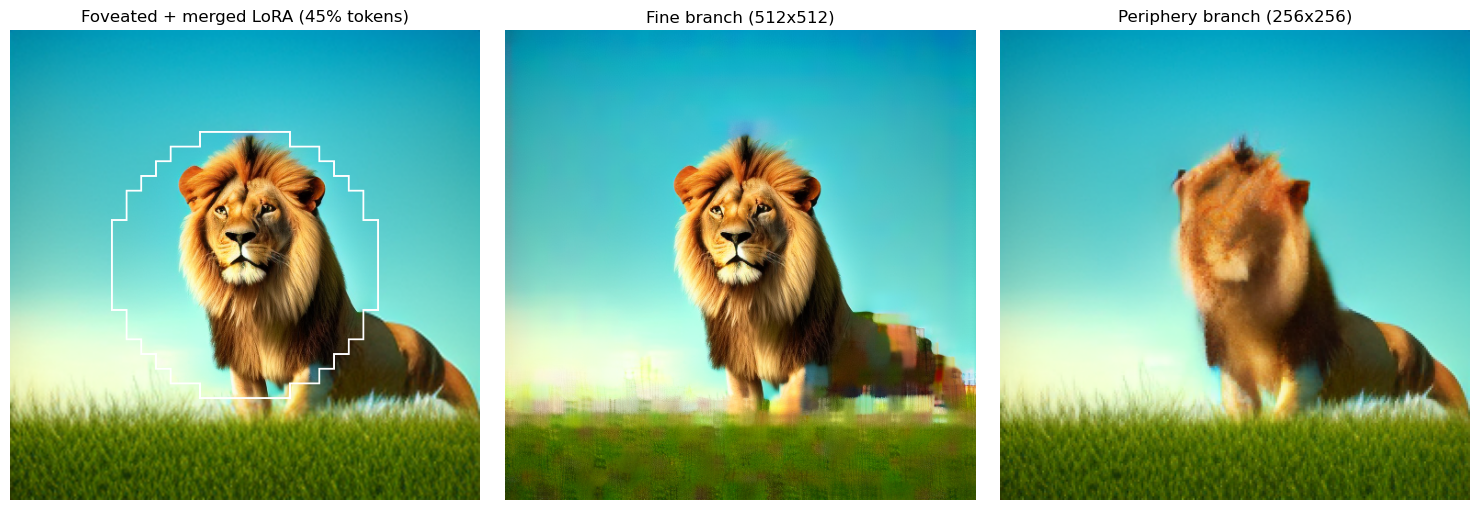

In [13]:
latents_out = run_foveated_loop(layout, test_embeds, test_mask, seed=40, steps=20,
                                guidance_scale=3.5, model=lora_transformer)
img_blend, img_hi, img_lo = decode_foveated(latents_out, layout, smooth=True)
img_with_border = draw_fovea_border(img_blend, layout)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img_with_border)
axs[0].set_title(f"Foveated + merged LoRA ({layout['token_ratio']*100:.0f}% tokens)")
axs[0].axis("off")

axs[1].imshow(img_hi)
axs[1].set_title("Fine branch (512x512)")
axs[1].axis("off")

axs[2].imshow(img_lo)
axs[2].set_title("Periphery branch (256x256)")
axs[2].axis("off")

plt.tight_layout()
plt.show()

### 🟠5.5) the trained LoRA with the fovea in different places
Same prompt, seed, guidance and fovea size as the image above; only the position of the fovea changes. The five single foveae sit inside the range of centres used in training ($[0.25, 0.75]^2$), so the model has seen fovea positions like these. The last panel has two smaller, disjoint foveae - a layout the LoRA never saw, since training uses one circle per step - which tests whether it generalises beyond its training masks (the paper's Fig. 9 shows this for its model). Compare with the naive model under similar masks in section 4.5.

Needs the 5.4 cells above (`lora_transformer`, `test_embeds`, `test_mask`); it generates with section 4's `run_foveated_loop` and `decode_foveated(smooth=True)`, like 5.4. Each image is also saved as `lora_fovea_<position>.png`.

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

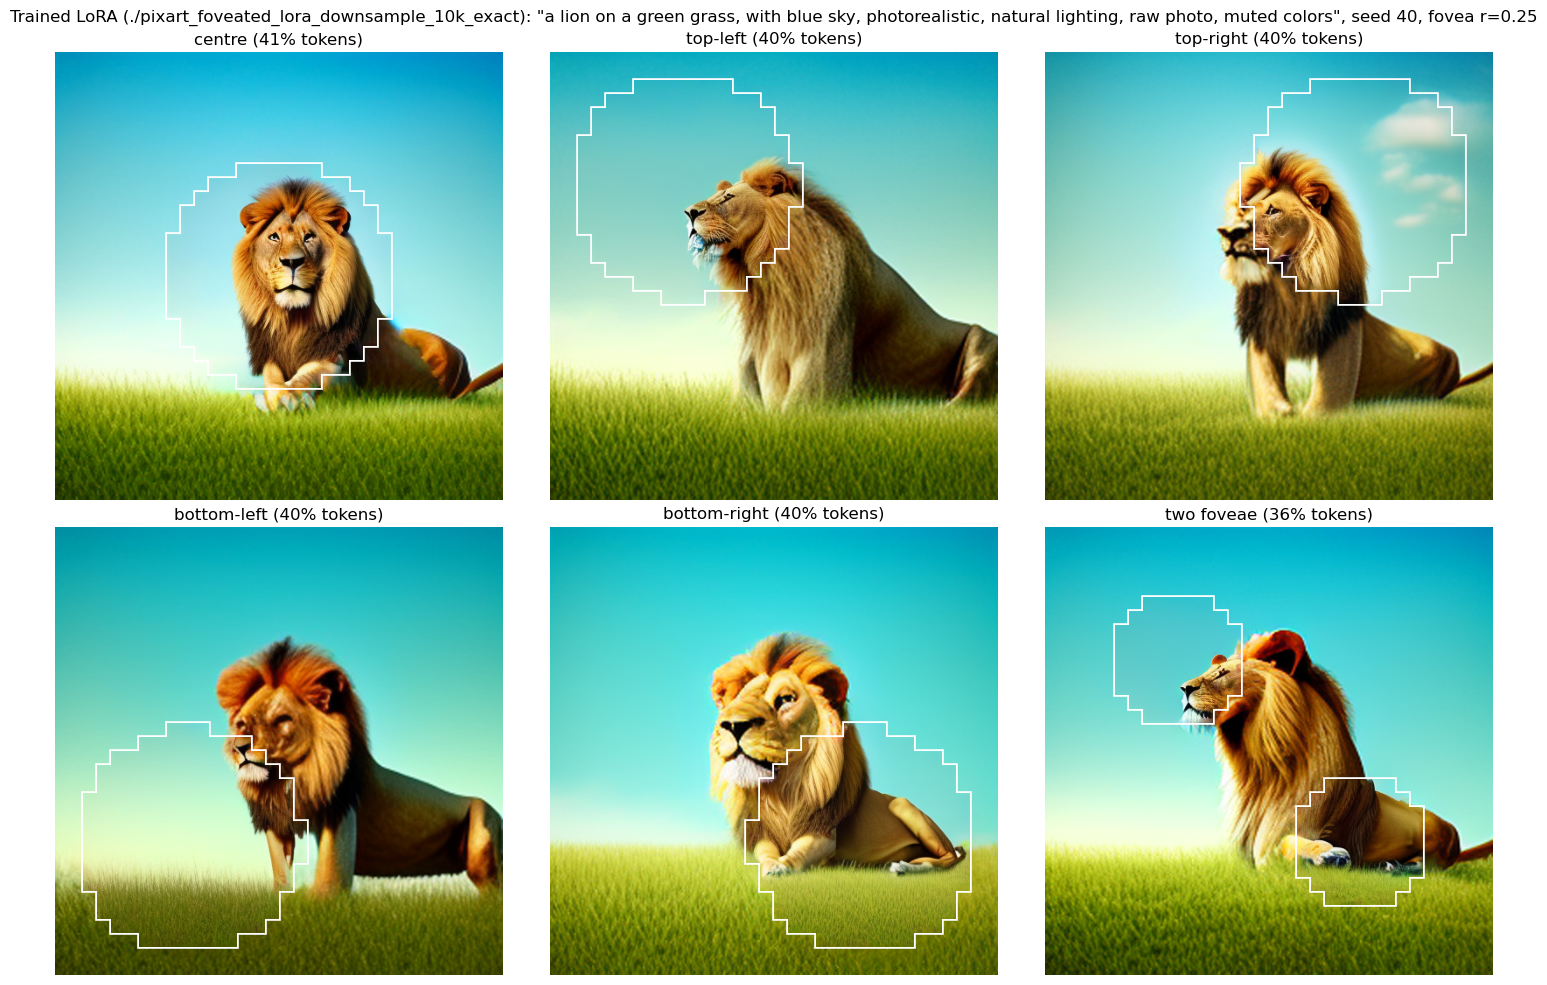

In [14]:
# 5.5) the trained LoRA with the fovea in different places: same prompt, seed and fovea size
F_SEED, F_STEPS, F_GUIDANCE, F_RADIUS = 40, 20, 3.5, 0.25   # guidance as in the 5.4 generation cell

placements = {
    "centre":       make_circular_mask((0.5, 0.5), F_RADIUS, grid=GRID),
    "top-left":     make_circular_mask((0.3, 0.3), F_RADIUS, grid=GRID),
    "top-right":    make_circular_mask((0.3, 0.7), F_RADIUS, grid=GRID),
    "bottom-left":  make_circular_mask((0.7, 0.3), F_RADIUS, grid=GRID),
    "bottom-right": make_circular_mask((0.7, 0.7), F_RADIUS, grid=GRID),
    "two foveae":   make_circular_mask((0.3, 0.3), 0.15, grid=GRID) | make_circular_mask((0.7, 0.7), 0.15, grid=GRID),
}

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, M) in zip(axs.flat, placements.items()):
    lay = build_layout(M)
    x = run_foveated_loop(lay, test_embeds, test_mask, seed=F_SEED, steps=F_STEPS,
                          guidance_scale=F_GUIDANCE, model=lora_transformer)
    img = decode_foveated(x, lay, smooth=True)[0]
    img.save(f"lora_fovea_{name.replace(' ', '_')}.png")
    ax.imshow(draw_fovea_border(img, lay))
    ax.set_title(f"{name} ({lay['token_ratio']:.0%} tokens)")
    ax.axis("off")

plt.suptitle(f'Trained LoRA ({lora_dir}): "{test_prompt}", seed {F_SEED}, fovea r={F_RADIUS}', fontsize=12)
plt.tight_layout()
plt.show()

# 🔵6) Gabor foveation masks
Our extension: instead of a random circle, the fovea goes where the image has the most oriented edge and texture energy, measured with Gabor filters - the classic model of V1 simple-cell receptive fields.
- **Filter bank:** 4 orientations (0°, 45°, 90°, 135°), kernel 31x31, σ = 4, wavelength λ = 10, aspect ratio γ = 0.5.
- **Mask:** the grayscale image is filtered with each kernel; the energy at each pixel is the largest absolute response over the orientations, normalised to [0, 1], smoothed with a Gaussian blur (`blur_size`), normalised again and thresholded (`threshold`) into a binary mask.
- **Token grid:** the 512x512 mask is reduced to the 32x32 token grid by majority vote over each token's 16x16 pixels.

The mask is computed from an existing image: during training from each training image, and at inference from a reference image (`example.png`), not from the image being generated. The cells below show the mask of `example.png` and how threshold and blur change the token mask and its token budget.

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def build_gabor_filters():
    """
    A bank of Gabor filters at 4 orientations (0, 45, 90, 135 degrees).
    ksize, sigma and lambd set the scale: larger values respond to coarser textures.
    """
    filters = []
    ksize = 31      # kernel size in pixels (must be odd)
    sigma = 4.0     # std of the Gaussian envelope
    lambd = 10.0    # wavelength of the sinusoid
    gamma = 0.5     # spatial aspect ratio (ellipticity)
    psi = 0         # phase offset

    for theta in [0, np.pi/4, np.pi/2, np.pi*3/4]:
        kern = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, psi, ktype=cv2.CV_32F)
        kern /= 1.5 * kern.sum()
        filters.append(kern)
    return filters

def generate_gabor_mask(image, threshold=0.4, blur_size=51):
    """
    Gabor energy mask of a PIL image. Returns (smoothed energy in [0, 1], binary mask), both HxW.
    """
    img_gray = np.array(image.convert("L"))

    filters = build_gabor_filters()

    # energy = the strongest absolute response over the orientations
    gabor_response = np.zeros_like(img_gray, dtype=np.float32)
    for kern in filters:
        fimg = cv2.filter2D(img_gray, cv2.CV_32F, kern)
        gabor_response = np.maximum(gabor_response, np.abs(fimg))

    # normalise the response to [0, 1]
    gabor_response = (gabor_response - gabor_response.min()) / (gabor_response.max() - gabor_response.min() + 1e-5)

    # strong Gaussian blur, so the scattered edge responses merge into continuous regions
    smoothed_mask = cv2.GaussianBlur(gabor_response, (blur_size, blur_size), 0)
    smoothed_mask = (smoothed_mask - smoothed_mask.min()) / (smoothed_mask.max() - smoothed_mask.min() + 1e-5)

    # binary mask by threshold
    binary_mask = (smoothed_mask > threshold).astype(np.float32)

    return smoothed_mask, binary_mask

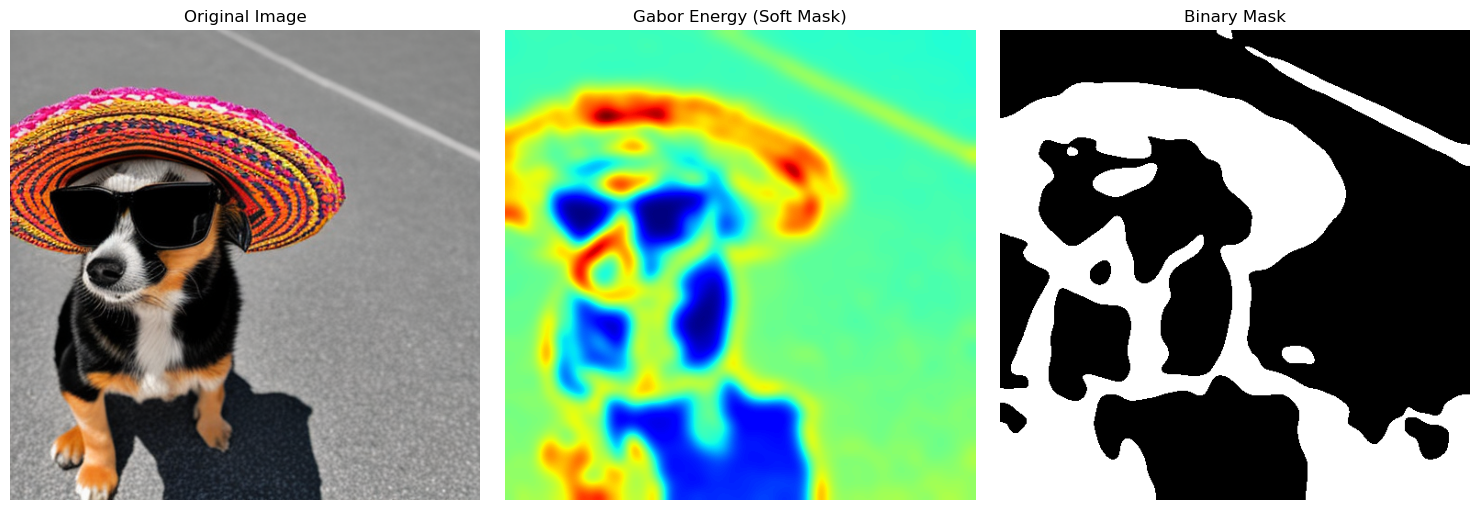

In [16]:
image_path = r"./example.png" 


img = Image.open(image_path).convert("RGB").resize((512, 512))
soft_mask, bin_mask = generate_gabor_mask(img, threshold=0.5, blur_size=51)

# show the image, its Gabor energy and the binary mask
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img)
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(soft_mask, cmap='jet')
axs[1].set_title("Gabor Energy (Soft Mask)")
axs[1].axis('off')

axs[2].imshow(bin_mask, cmap='gray')
axs[2].set_title("Binary Mask")
axs[2].axis('off')

plt.tight_layout()
plt.show()

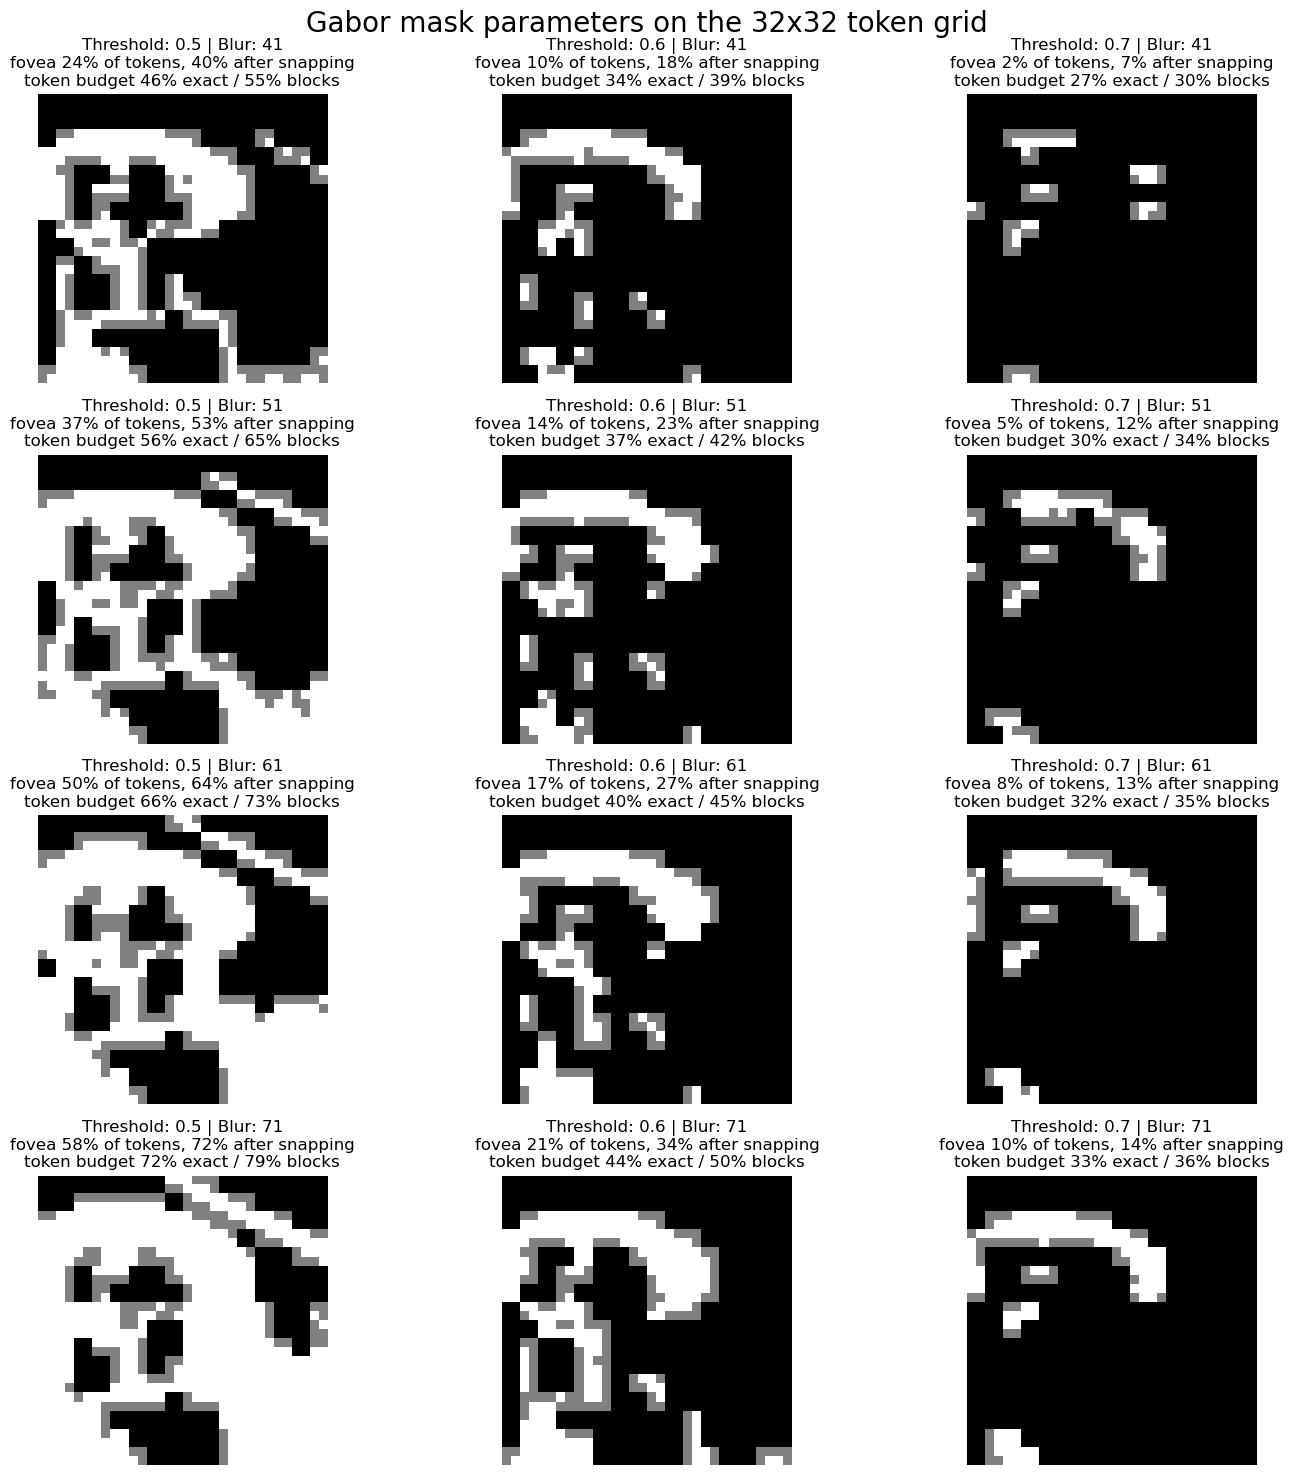

In [17]:
# The same threshold/blur sweep, but shown the way the model actually consumes it: the 512x512
# binary mask reduced to the 32x32 token grid, the identical reduction gabor_token_mask does in 6.1a.
# White = fovea at token resolution, grey = tokens that 2x2 block snapping adds on top of it.
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

thresholds = [0.5,0.6, 0.7]
blur_sizes = [41, 51, 61, 71]
TOKEN_GRID = 32            # 512 / (8 VAE * 2 patch): one token covers 16x16 pixels

def to_token_grid(bin_mask, grid=TOKEN_GRID):
    """Majority vote over each token's 16x16 pixels."""
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5

def routing(M):
    """Block-snapped fovea, and what each routing mode costs out of grid*grid fine tokens."""
    blk = M.reshape(M.shape[0] // 2, 2, M.shape[1] // 2, 2)
    snapped = blk.any(dim=3).any(dim=1)          # a block is fovea if any of its 4 tokens is
    full = blk.all(dim=3).all(dim=1)             # only these give up their coarse token
    n_exact = int(M.sum()) + int((~full).sum())  # fine tokens + one coarse per not-fully-fovea block
    n_snap = 4 * int(snapped.sum()) + int((~snapped).sum())
    M_snap = snapped.repeat_interleave(2, 0).repeat_interleave(2, 1)
    return M_snap, n_exact / M.numel(), n_snap / M.numel()

fig, axs = plt.subplots(len(blur_sizes), len(thresholds), figsize=(15, 15))
fig.suptitle(f"Gabor mask parameters on the {TOKEN_GRID}x{TOKEN_GRID} token grid", fontsize=20, y=0.98)

for i, b_size in enumerate(blur_sizes):
    for j, thresh in enumerate(thresholds):
        _, bin_mask = generate_gabor_mask(img, threshold=thresh, blur_size=b_size)
        M = to_token_grid(bin_mask)
        M_snap, r_exact, r_snap = routing(M)

        vis = M.float()
        vis[M_snap & ~M] = 0.5
        axs[i, j].imshow(vis, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axs[i, j].set_title(f"Threshold: {thresh} | Blur: {b_size}\n"
                            f"fovea {M.float().mean():.0%} of tokens, {M_snap.float().mean():.0%} after snapping\n"
                            f"token budget {r_exact:.0%} exact / {r_snap:.0%} blocks", fontsize=12)
        axs[i, j].axis("off")

plt.tight_layout()
plt.show()


### 🟠6.1) LoRA trained on Gabor foveation masks
A second LoRA, trained like section 5 but with the fovea placed by each image's own Gabor energy instead of a random circle. Each of the 10,000 DiffusionDB images gets exactly one mask, `generate_gabor_mask(image, threshold=G_THRESHOLD, blur_size=G_BLUR)` computed on the same 512×512 resize the VAE sees and reduced to the 32×32 token grid by majority vote. Training is a single shuffled pass, one step per image, with the same LoRA, loss and optimiser settings as section 5 and a 55-minute limit. Trained runs: threshold 0.5 with blur 51 and with blur 61 (`..._b51_exact`, `..._b61_exact`); `G_BLUR` in the next cell selects the run.

Needs the section 5 config cell (`device`, `model_id`) and the Gabor cell (`generate_gabor_mask`). It shares the 10k latent cache with section 5 (`diffusiondb_512_cached_downsample_10k.pt`) and writes its own mask file and LoRA directory.

In [18]:
# 6.1a) data: 10k text embeddings, latents (fine + E(Down(x))) and one Gabor mask per image
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

G_N_IMAGES   = 10000
G_DB_CONFIG  = f"2m_random_{G_N_IMAGES // 1000}k"
G_THRESHOLD  = 0.5
G_BLUR       = 61          # Gaussian kernel size in 512x512 pixels, must be odd
G_TAG        = f"gabor_{G_N_IMAGES // 1000}k_t{G_THRESHOLD}_b{G_BLUR}_exact"   # masks at token resolution
g_lora_dir   = f"./pixart_foveated_lora_{G_TAG}"
g_cache_file = f"diffusiondb_512_cached_downsample_{G_N_IMAGES // 1000}k.pt"   # latents + text
g_mask_file  = f"gabor_masks_{G_N_IMAGES // 1000}k_t{G_THRESHOLD}_b{G_BLUR}.pt"
G_TEXT_LEN   = 120
G_FORCE      = False       # True retrains even if g_lora_dir already exists

g_resize = T.Resize((512, 512))     # the resize both the VAE and the mask see, so they line up

def gabor_token_mask(image, grid=32):
    """(grid, grid) bool mask: each token is fovea if most of its 16x16 pixels pass the threshold."""
    _, bin_mask = generate_gabor_mask(g_resize(image.convert("RGB")),
                                      threshold=G_THRESHOLD, blur_size=G_BLUR)
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5

def g_free(names):
    """Drop notebook globals and hand their memory back. Anything still referenced elsewhere stays."""
    for var in names:
        globals().pop(var, None)
    gc.collect()
    torch.cuda.empty_cache()

# Everything earlier cells may have left on the GPU or in RAM. The big ones: the CVAE cell above
# keeps a second T5 on the GPU and ~10 GB of padded fp32 text embeddings (`training_data`) in RAM;
# sections 3-5 each keep a transformer and a VAE. `base_model` and `transformer` both have to go,
# because either one alone keeps the whole transformer alive.
G_EARLIER = ["text_encoder", "tokenizer", "training_data", "transformer", "base_model", "vae",
             "optimizer", "trainable", "x0_all", "x0_lo_all", "cached_text_embeds",
             "cached_text_masks", "cached_x0", "cached_x0_lo", "latents_out", "cvae",
             "g_transformer", "g_base", "g_opt", "g_trainable", "g_x0_all", "g_x0_lo_all",
             "lora_transformer"]

def g_load_dataset():
    from datasets import load_dataset
    try:
        return load_dataset("poloclub/diffusiondb", G_DB_CONFIG, split="train", trust_remote_code=True)
    except TypeError:
        return load_dataset("poloclub/diffusiondb", G_DB_CONFIG, split="train")

if os.path.exists(g_lora_dir) and not G_FORCE:
    print(f" Gabor LoRA already trained at '{g_lora_dir}'. Nothing to prepare.")

else:
    g_free(G_EARLIER)
    print(f"VRAM allocated after cleanup: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    g_dataset = None

    # --- latents and text: the expensive part, cached independently of the Gabor parameters ---
    if os.path.exists(g_cache_file):
        print(f" Loading '{g_cache_file}'...")
        d = torch.load(g_cache_file, map_location="cpu")
        g_text_embeds, g_text_masks, g_x0, g_x0_lo = d["text_embeds"], d["text_masks"], d["x0"], d["x0_lo"]
        del d
    else:
        g_dataset = g_load_dataset()

        print(f" Encoding {len(g_dataset):,} prompts with T5...")
        tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
        text_encoder = T5EncoderModel.from_pretrained(
            model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)
        g_text_embeds, g_text_masks = [], []
        with torch.no_grad():
            for prompt in tqdm(g_dataset["prompt"], desc="T5"):
                tok = tokenizer(prompt, padding="max_length", max_length=G_TEXT_LEN,
                                truncation=True, return_tensors="pt").to(device)
                emb = text_encoder(tok.input_ids, attention_mask=tok.attention_mask)[0]
                n = int(tok.attention_mask[0].sum())          # keep real tokens only; re-padded later
                g_text_embeds.append(emb[:, :n].cpu())
                g_text_masks.append(tok.attention_mask[:, :n].cpu())
        del text_encoder, tokenizer
        gc.collect(); torch.cuda.empty_cache()

        print(f" Encoding {len(g_dataset):,} images with the VAE (fine + E(Down(x)))...")
        vae_enc = AutoencoderKL.from_pretrained(model_id, subfolder="vae",
                                                torch_dtype=torch.bfloat16).to(device)
        SF = vae_enc.config.scaling_factor
        to_tensor = T.Compose([g_resize, T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])
        g_x0, g_x0_lo = [], []
        with torch.no_grad():
            for item in tqdm(g_dataset, desc="VAE"):
                x = to_tensor(item["image"].convert("RGB")).unsqueeze(0).to(device, torch.bfloat16)
                g_x0.append((vae_enc.encode(x).latent_dist.mean * SF).cpu())
                x_lo = F.interpolate(x.float(), scale_factor=0.5, mode="bicubic",
                                     antialias=True).clamp(-1, 1).to(x.dtype)
                g_x0_lo.append((vae_enc.encode(x_lo).latent_dist.mean * SF).cpu())
        del vae_enc
        gc.collect(); torch.cuda.empty_cache()

        # same keys and format as the section 5 cache, so either section can reuse this file
        torch.save({"text_embeds": g_text_embeds, "text_masks": g_text_masks, "x0": g_x0,
                    "x0_lo": g_x0_lo, "target_mode": "downsample", "db_config": G_DB_CONFIG,
                    "text_max_len": G_TEXT_LEN}, g_cache_file)
        print(f" Saved '{g_cache_file}'.")

    # --- Gabor masks: cheap, cached per (threshold, blur) ---
    if os.path.exists(g_mask_file):
        g_masks = torch.load(g_mask_file, map_location="cpu")["masks"]
        print(f" Loaded {len(g_masks)} Gabor masks from '{g_mask_file}'.")
    else:
        if g_dataset is None:
            g_dataset = g_load_dataset()
        # same subset in the same order as the latent cache, so mask i belongs to latent i
        g_masks = torch.stack([gabor_token_mask(item["image"])
                               for item in tqdm(g_dataset, desc="Gabor masks")])
        torch.save({"masks": g_masks, "threshold": G_THRESHOLD, "blur": G_BLUR,
                    "db_config": G_DB_CONFIG}, g_mask_file)
        print(f" Saved {len(g_masks)} Gabor masks to '{g_mask_file}'.")

    assert len(g_masks) == len(g_x0) == len(g_x0_lo) == len(g_text_embeds), "cache / mask size mismatch"

    area = g_masks.float().mean(dim=(1, 2))
    print(f"fovea area per image: mean {area.mean():.0%}, median {area.median():.0%}, "
          f"min {area.min():.0%}, max {area.max():.0%}; "
          f"{int((area == 0).sum())} empty, {int((area == 1).sum())} full")

    # a few masks, so a bad threshold shows up before the hour of training rather than after
    fig, axs = plt.subplots(1, 6, figsize=(15, 2.8))
    for ax, i in zip(axs, torch.linspace(0, len(g_masks) - 1, 6).long().tolist()):
        ax.imshow(g_masks[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"#{i}: {area[i]:.0%}")
        ax.axis("off")
    plt.suptitle(f"Gabor training masks (t={G_THRESHOLD}, blur={G_BLUR}) on the 32x32 token grid")
    plt.tight_layout()
    plt.show()

 Gabor LoRA already trained at './pixart_foveated_lora_gabor_10k_t0.5_b61_exact'. Nothing to prepare.


In [19]:
# 6.1b) train the Gabor LoRA: one pass over the 10k images, each with its own Gabor mask
import os
import gc
import math
import random
import time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from peft import LoraConfig, get_peft_model
from diffusers import Transformer2DModel, DPMSolverMultistepScheduler
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

def gabor_token_mask(image, grid=32):
    """(grid, grid) bool mask: each token is fovea if most of its 16x16 pixels pass the threshold."""
    _, bin_mask = generate_gabor_mask(g_resize(image.convert("RGB")),
                                      threshold=G_THRESHOLD, blur_size=G_BLUR)
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5
if os.path.exists(g_lora_dir) and not G_FORCE:
    print(f" Gabor LoRA already trained at '{g_lora_dir}'. Set G_FORCE=True to retrain.")

elif "g_masks" not in globals():
    print(" Run the data cell (6.1a) first.")

else:
    # Free whatever earlier sections left behind, including a previous run of this cell, before
    # loading a fresh transformer: otherwise a rerun holds two of them on the GPU.
    g_free(G_EARLIER)
    print(f"VRAM allocated after cleanup: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

    g_transformer = Transformer2DModel.from_pretrained(
        model_id, subfolder="transformer", torch_dtype=torch.bfloat16).to(device)
    g_transformer = get_peft_model(g_transformer, LoraConfig(     # same LoRA as section 5
        r=32, lora_alpha=64, lora_dropout=0.05, bias="none",
        target_modules=["to_q", "to_k", "to_v", "to_out.0", "net.0.proj", "net.2"]))
    g_transformer.enable_gradient_checkpointing()
    g_transformer.print_trainable_parameters()
    g_base = g_transformer.base_model.model

    gP, gC, gD = g_base.config.patch_size, g_base.config.in_channels, g_base.inner_dim
    g_pe = g_base.pos_embed
    G_GRID = g_pe.height
    G_POS_SCALE = g_pe.base_size / g_pe.height / g_pe.interpolation_scale

    def g_patchify(z):
        B, c, H, W = z.shape
        return z.reshape(B, c, H // gP, gP, W // gP, gP).permute(0, 2, 4, 3, 5, 1) \
                .reshape(B, (H // gP) * (W // gP), gP * gP * c)

    def g_build_layout(M):
        """Same layout as section 4's build_layout: the mask at token resolution, fine tokens inside M
        and one coarse token for every 2x2 block that is not entirely fovea, so a partly-foveal block
        carries both kinds. Positions on the fine grid."""
        h, w = M.shape
        Mb = M.reshape(h // 2, 2, w // 2, 2).all(dim=3).all(dim=1)
        hi_idx = M.flatten().nonzero().squeeze(1)
        lo_idx = (~Mb).flatten().nonzero().squeeze(1)
        ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
        hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
        ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
        lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5
        xy = torch.cat([hi_xy, lo_xy]) * G_POS_SCALE
        pos = get_2d_sincos_pos_embed_from_grid(gD, xy.T.to(device), output_type="pt").float()[None]
        return dict(hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos)

    def g_get_text(idx):
        emb, mask = g_text_embeds[idx], g_text_masks[idx]
        pad = G_TEXT_LEN - emb.shape[1]
        if pad > 0:                       # padded positions are masked to -10000, so zeros are exact
            emb, mask = F.pad(emb, (0, 0, 0, pad)), F.pad(mask, (0, pad))
        return emb.to(device=device, dtype=torch.bfloat16), mask.to(device)

    def g_forward(x, t, layout, p_emb, p_mask):
        B = x.shape[0]
        W_in = g_pe.proj.weight.permute(0, 2, 3, 1).reshape(gD, gP * gP * gC).to(x.dtype)
        bias = g_pe.proj.bias.to(x.dtype) if g_pe.proj.bias is not None else None
        h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)
        t_emb, t_raw = g_base.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                           batch_size=B, hidden_dtype=h.dtype)
        enc = g_base.caption_projection(p_emb).view(B, -1, gD)
        enc_bias = ((1 - p_mask.to(h.dtype)) * -10000.0).unsqueeze(1)
        for block in g_base.transformer_blocks:
            h = block(h, attention_mask=None, encoder_hidden_states=enc,
                      encoder_attention_mask=enc_bias, timestep=t_emb,
                      cross_attention_kwargs=None, class_labels=None)
        shift, scale = (g_base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
        out = g_base.proj_out(g_base.norm_out(h) * (1 + scale) + shift)
        return out.reshape(B, -1, gP * gP, g_base.out_channels)[..., :gC].reshape(B, -1, gP * gP * gC)

    g_sched = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")
    g_alphas = g_sched.alphas_cumprod.float().cpu()

    g_trainable = [p for p in g_transformer.parameters() if p.requires_grad]
    g_opt = torch.optim.AdamW(g_trainable, lr=1e-4, weight_decay=1e-2)

    g_x0_all = torch.cat(g_x0).to(device=device, dtype=torch.bfloat16)
    g_x0_lo_all = torch.cat(g_x0_lo).to(device=device, dtype=torch.bfloat16)

    ACCUM, BASE_LR, WARMUP = 4, 1e-4, 200
    num_steps, max_minutes = len(g_masks), 55      # one step per image = one pass

    g_transformer.train()
    order = torch.randperm(len(g_masks)).tolist()
    ema, g_loss_hist, start = None, [], time.time()
    g_opt.zero_grad(set_to_none=True)
    bar = tqdm(range(num_steps), desc=f"Training LoRA ({G_TAG})")

    for step in bar:
        elapsed = (time.time() - start) / 60
        if elapsed > max_minutes:
            print(f"\nReached the {max_minutes}-minute limit after {step} steps.")
            break

        lr = (BASE_LR * (step + 1) / WARMUP if step < WARMUP else
              BASE_LR * 0.5 * (1 + math.cos(math.pi * (step - WARMUP) / max(1, num_steps - WARMUP))))
        for pg in g_opt.param_groups:
            pg["lr"] = lr

        idx = order.pop()
        layout = g_build_layout(g_masks[idx])          # this image's own Gabor mask
        p_emb, p_mask = g_get_text(idx)

        ti = random.randrange(1000)
        a = float(g_alphas[ti])
        t = torch.tensor([ti], device=device, dtype=torch.long)

        # fovea and periphery each run their own forward process (paper Eqs. 8-9)
        x0, x0_lo = g_x0_all[idx:idx + 1], g_x0_lo_all[idx:idx + 1]
        noise, noise_lo = torch.randn_like(x0), torch.randn_like(x0_lo)
        x_t = a ** 0.5 * x0 + (1 - a) ** 0.5 * noise
        x_t_lo = a ** 0.5 * x0_lo + (1 - a) ** 0.5 * noise_lo

        x_in = torch.cat([g_patchify(x_t)[:, layout["hi_idx"]],
                          g_patchify(x_t_lo)[:, layout["lo_idx"]]], dim=1)
        target = torch.cat([g_patchify(noise)[:, layout["hi_idx"]],
                            g_patchify(noise_lo)[:, layout["lo_idx"]]], dim=1)

        loss = F.mse_loss(g_forward(x_in, t, layout, p_emb, p_mask), target)
        (loss / ACCUM).backward()
        if (step + 1) % ACCUM == 0:
            torch.nn.utils.clip_grad_norm_(g_trainable, max_norm=1.0)
            g_opt.step()
            g_opt.zero_grad(set_to_none=True)

        l = loss.item()
        ema = l if ema is None else 0.99 * ema + 0.01 * l
        g_loss_hist.append(ema)
        bar.set_postfix({"Loss(ema)": f"{ema:.4f}", "lr": f"{lr:.1e}", "Time": f"{elapsed:.1f}m"})

        if (step + 1) % 2500 == 0:
            g_transformer.save_pretrained(f"./checkpoint_{G_TAG}_step_{step + 1}")

    g_transformer.save_pretrained(g_lora_dir)
    print(f"\nTrained {len(g_loss_hist)} steps in {(time.time() - start) / 60:.1f} min. "
          f"Saved to '{g_lora_dir}'.")

    del g_x0_all, g_x0_lo_all, g_opt, g_trainable
    gc.collect(); torch.cuda.empty_cache()

    plt.figure(figsize=(7, 3.5))
    plt.plot(g_loss_hist, lw=1)
    plt.xlabel("step"); plt.ylabel("MSE (ema)")
    plt.title(f"LoRA training loss, {G_TAG}")
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

 Gabor LoRA already trained at './pixart_foveated_lora_gabor_10k_t0.5_b61_exact'. Set G_FORCE=True to retrain.


### 🟠6.2) generating with the Gabor LoRA: centred fovea
One image from the Gabor LoRA in `g_lora_dir` (the run selected by `G_BLUR` in 6.1a), with a centred circular fovea (r = 0.28, as in section 5.4). Section 7 compares this model with the others under the same and other masks.

Generation uses section 4's `run_foveated_loop` with the LoRA-merged transformer passed as `model=`, and section 4's plain `decode_foveated` (hard blend). Needs sections 3.1, 3.2 and 4.1-4.3 (the shared loop and helpers) and cell 6.1a (`g_free`, `g_lora_dir`; 6.1a skips straight through when the LoRA already exists). The image is saved as `gabor_lora_center.png`.

Some weights of the model checkpoint were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

centred circle, r=0.28: 45% tokens, 8.7s -> gabor_lora_center.png


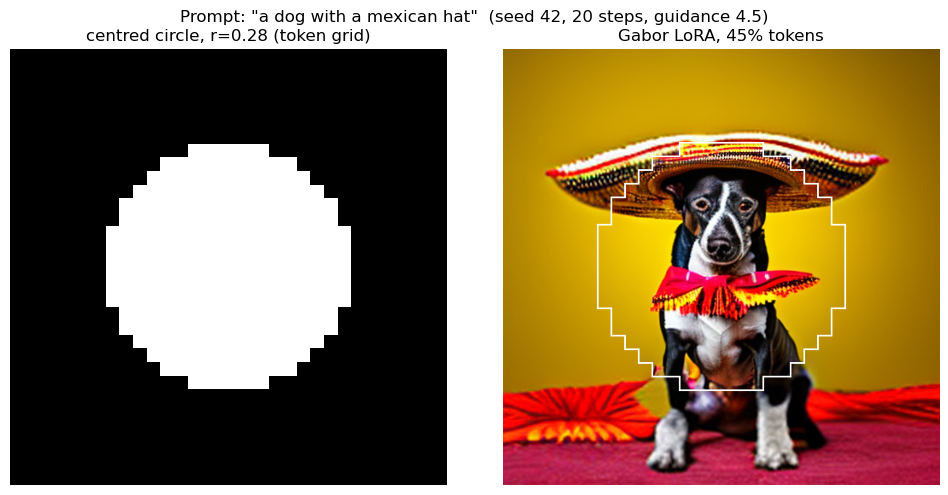

In [20]:
# 6.2) inference with the Gabor LoRA, centred fovea.
#      Uses section 4's loop and decoder (build_layout, run_foveated_loop, decode_foveated).
import gc
import time
import torch
import matplotlib.pyplot as plt
from peft import PeftModel
from diffusers import Transformer2DModel, AutoencoderKL, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer

I_PROMPT   = "a dog with a mexican hat"
I_SEED     = 42
I_STEPS    = 20
I_GUIDANCE = 4.5
I_RADIUS   = 0.28             # centred circle, as in section 5.4

# free the training leftovers and earlier sections' models before loading the merged one
g_free(G_EARLIER + ["i_transformer"])

# 1. the transformer with the Gabor LoRA merged in (fp16, like the base model of 3.2), and the
#    VAE / scheduler globals that section 4's functions use
i_transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.float16).to(device)
i_transformer = PeftModel.from_pretrained(i_transformer, g_lora_dir).merge_and_unload().eval()
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float16).to(device)
if "scheduler" not in globals():
    scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# 2. prompt, ordered [unconditional, prompt] - the order run_foveated_loop's CFG split expects
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)
with torch.no_grad():
    tok = tokenizer(["", I_PROMPT], padding="max_length", max_length=G_TEXT_LEN,
                    truncation=True, return_tensors="pt").to(device)
    i_embeds = text_encoder(tok.input_ids, attention_mask=tok.attention_mask)[0]
    i_text_mask = tok.attention_mask
del text_encoder, tokenizer
gc.collect(); torch.cuda.empty_cache()

# 3. generate with a centred fovea
layout = build_layout(make_circular_mask((0.5, 0.5), I_RADIUS))
torch.cuda.synchronize(); t0 = time.time()
x = run_foveated_loop(layout, i_embeds, i_text_mask, seed=I_SEED, steps=I_STEPS,
                      guidance_scale=I_GUIDANCE, model=i_transformer)
img = decode_foveated(x, layout)[0]
torch.cuda.synchronize(); dt = time.time() - t0
img.save("gabor_lora_center.png")
print(f"centred circle, r={I_RADIUS}: {layout['token_ratio']:.0%} tokens, {dt:.1f}s -> gabor_lora_center.png")

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(layout["M"], cmap="gray", vmin=0, vmax=1)
axs[0].set_title(f"centred circle, r={I_RADIUS} (token grid)")
axs[1].imshow(draw_fovea_border(img, layout))
axs[1].set_title(f"Gabor LoRA, {layout['token_ratio']:.0%} tokens")
for ax in axs:
    ax.axis("off")
plt.suptitle(f'Prompt: "{I_PROMPT}"  (seed {I_SEED}, {I_STEPS} steps, guidance {I_GUIDANCE})')
plt.tight_layout()
plt.show()

# 🔵7) comparing the LoRAs: seeds × trainings
To robustly evaluate the models, we generated images across 30 diverse text prompts using 3 random seeds per prompt (yielding 90 images per configuration). Each evaluated model was subjected to identical foveation masks, isolating the impact of the training strategy. We evaluated three distinct spatial layouts:

* **Centred circle** ($r = 0.28$), as described in the training sections.
* **Top-left circle** ($r = 0.28$, centre at $0.3, 0.3$): evaluating the same foveal size in an asymmetric, off-center position.
* **Two foveae** ($r = 0.15$ each, centres at $0.3, 0.3$ and $0.7, 0.7$): a complex layout that the Random-mask LoRA never encountered during training (which utilized only single circles). In contrast, the Gabor-mask LoRA was exposed to similar multi-region layouts due to the inherent structure of Gabor filters.

We compared four configurations: the full high-resolution base model (serving as the reference standard), the na"ive baseline (base model, no LoRA), the Random-mask LoRA (trained on 10k images for 1 epoch), and our Gabor-mask LoRA. All foveated generations were executed at token resolution, and the foveal seams were softened using a consistent blending mechanism (`smooth=True`). To ensure an unbiased comparison, all generation parameters were fixed, including 20 inference steps with DPM-Solver and a classifier-free guidance (CFG) scale of 2.5. 

The quantitative results are consolidated into a single table reporting the token ratio, inference time (in seconds), and CLIP score (to measure semantic alignment). We report the mean and standard deviation across all 90 generated images per layout. With 30 diverse prompts, these metrics provide a statistically robust foundation to evaluate both the computational efficiency gains and the semantic fidelity of the tested models compared to the full-resolution reference.

Needs sections 3.1, 3.2 and 4.1-4.3 (the shared loop and helpers).

In [24]:
import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from peft import PeftModel
from diffusers import Transformer2DModel, AutoencoderKL, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer, CLIPProcessor, CLIPModel

# 30 Diverse Prompts for robust evaluation
CMP_PROMPTS = [
    "a lion on a green grass, with blue sky",
    "a futuristic city skyline at sunset, cyberpunk style",
    "a close up portrait of an old man with deep wrinkles",
    "a cute fluffy golden retriever playing with a red ball",
    "a majestic snowy mountain peak under a starry night",
    "a cup of hot coffee on a wooden table, morning light",
    "a highly detailed oil painting of a medieval knight",
    "a sports car driving fast on a wet neon-lit street",
    "a beautiful coral reef underwater with colorful fish",
    "an astronaut floating in outer space near earth",
    "a magical forest with glowing mushrooms and fairies",
    "a delicious pepperoni pizza fresh out of the oven",
    "a macro shot of a dew drop on a green leaf",
    "a steampunk airship flying through clouds",
    "a cozy living room with a fireplace and a cat",
    "a dramatic volcanic eruption with bright red lava",
    "a delicate glass butterfly resting on a flower",
    "a wide shot of a desert landscape with sand dunes",
    "a realistic photograph of a tiger in the jungle",
    "a crowded futuristic street market with flying cars",
    "a serene waterfall hidden deep in a lush jungle",
    "a robot painting a picture on a canvas",
    "a plate of colorful sushi on a dark slate background",
    "a highly detailed sketch of a vintage pocket watch",
    "a giant kraken attacking a pirate ship in a storm",
    "a serene japanese zen garden with a koi pond",
    "a neon glowing geometric shape in a dark room",
    "a fierce dragon breathing fire over a ruined castle",
    "a photorealistic apple with water droplets",
    "a minimalist interior design with white furniture"
]

CMP_SEEDS    = [42, 100, 777]    # 3 seeds per prompt
CMP_STEPS    = 20
CMP_GUIDANCE = 2.5
CMP_RADIUS   = 0.28
CMP_TWO_R    = 0.15
CMP_SMOOTH   = True
CMP_SMOOTH_K, CMP_SMOOTH_SIGMA = 11, 8.0
CMP_OUT_DIR  = "./comparison_large"

CMP_MODELS = [
    ("full high-res (base)",  None,                                              False),
    ("naive (base, no LoRA)", None,                                              True),
    ("random fovea, 10k x 1", "./pixart_foveated_lora_downsample_10k_exact",     True),
    ("Gabor b51, 10k x 1",    "./pixart_foveated_lora_gabor_10k_t0.5_b51_exact", True),
]
for name, d, _ in CMP_MODELS:
    if d is not None and not os.path.exists(d):
        print(f" skipping '{name}': {d} not found")
CMP_MODELS = [m for m in CMP_MODELS if m[1] is None or os.path.exists(m[1])]

# Free RAM/VRAM before starting
for _v in ["text_encoder", "tokenizer", "transformer", "base_model", "vae", "optimizer", "trainable",
           "x0_all", "x0_lo_all", "cached_x0", "cached_x0_lo", "cached_text_embeds", "cached_text_masks",
           "latents_out", "training_data", "cvae", "i_transformer", "lora_transformer", "g_transformer", "g_base",
           "g_opt", "g_trainable", "g_x0_all", "g_x0_lo_all", "cmp_net"]:
    globals().pop(_v, None)
gc.collect(); torch.cuda.empty_cache()

# Load T5 explicitly to encode all prompts once
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)

def get_text_embeddings(prompt):
    with torch.no_grad():
        tok = tokenizer(["", prompt], padding="max_length", max_length=120, truncation=True, return_tensors="pt").to(device)
        embeds = text_encoder(tok.input_ids, attention_mask=tok.attention_mask)[0]
        return embeds, tok.attention_mask

print("Pre-calculating text embeddings...")
prompt_embeddings = {p: get_text_embeddings(p) for p in CMP_PROMPTS}

# Free T5 from VRAM
print("Freeing T5 text encoder from VRAM...")
del text_encoder, tokenizer
gc.collect(); torch.cuda.empty_cache()

# Load VAE and Scheduler
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float16).to(device)
if "scheduler" not in globals():
    scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

def cmp_load(lora_dir):
    net = Transformer2DModel.from_pretrained(model_id, subfolder="transformer", torch_dtype=torch.float16).to(device)
    if lora_dir is not None:
        net = PeftModel.from_pretrained(net, lora_dir).merge_and_unload()
    return net.eval()

def cmp_border(pil_img, M, color=(255, 255, 255)):
    m = F.interpolate(M.float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return Image.fromarray(arr)

CMP_MASKS = {
    "center":     (f"centred circle r={CMP_RADIUS}",  make_circular_mask((0.5, 0.5), CMP_RADIUS)),
    "top_left":   (f"top-left circle r={CMP_RADIUS}", make_circular_mask((0.3, 0.3), CMP_RADIUS)),
    "two_foveae": (f"two foveae r={CMP_TWO_R}", make_circular_mask((0.3, 0.3), CMP_TWO_R) | make_circular_mask((0.7, 0.7), CMP_TWO_R)),
}

# Load CLIP Model
print("Loading CLIP model for semantic metrics...")
clip_model_id = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(clip_model_id)
clip_model = CLIPModel.from_pretrained(clip_model_id).to(device).eval()

def cmp_clip_score(pil_img, prompt):
    inputs = clip_processor(text=[prompt], images=pil_img, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        outputs = clip_model(**inputs)
        return outputs.logits_per_image.item()

# --- MAIN GENERATION LOOP ---
os.makedirs(CMP_OUT_DIR, exist_ok=True)
full_layout = build_layout(torch.ones(GRID, GRID, dtype=torch.bool))
images, full_ref, rows = {}, {}, []
cmp_net, cmp_lora = None, "none loaded"

print(f"\nStarting Generation: {len(CMP_PROMPTS)} prompts * {len(CMP_SEEDS)} seeds per configuration.\n")

for name, lora_dir, foveated in CMP_MODELS:
    if lora_dir != cmp_lora:
        del cmp_net; gc.collect(); torch.cuda.empty_cache()
        print(f"Loading Model: {name}")
        cmp_net = cmp_load(lora_dir)
        cmp_lora = lora_dir
        
    for mask_key, (mask_name, M) in CMP_MASKS.items():
        layout = build_layout(M) if foveated else full_layout
        
        for p_idx, prompt in enumerate(CMP_PROMPTS):
            cmp_embeds, cmp_text_mask = prompt_embeddings[prompt]
            
            for seed in CMP_SEEDS:
                ref_key = (prompt, seed)
                
                # Base model has no fovea, so we only run it once per prompt+seed
                if not foveated and ref_key in full_ref:
                    pil, dt = full_ref[ref_key], float("nan")
                else:
                    torch.cuda.synchronize(); t0 = time.time()
                    x = run_foveated_loop(layout, cmp_embeds, cmp_text_mask, seed=seed, steps=CMP_STEPS,
                                          guidance_scale=CMP_GUIDANCE, model=cmp_net)
                    pil = decode_foveated(x, layout, smooth=CMP_SMOOTH and foveated,
                                          smooth_kernel=CMP_SMOOTH_K, smooth_sigma=CMP_SMOOTH_SIGMA)[0]
                    torch.cuda.synchronize(); dt = time.time() - t0
                    if not foveated:
                        full_ref[ref_key] = pil
                
                images[(mask_key, name, prompt, seed)] = pil
                
                # Save image to disk
                clean_name = name.replace(' ', '_').replace(',', '')
                filename = f"{mask_key}__{clean_name}__p{p_idx}__seed{seed}.png"
                pil.save(os.path.join(CMP_OUT_DIR, filename))
                
                # Calculate metrics (only CLIP and time)
                row = dict(prompt_idx=p_idx, mask=mask_name, model=name, seed=seed, token_ratio=layout["token_ratio"], seconds=dt)
                row["CLIP_Score"] = cmp_clip_score(pil, prompt)
                rows.append(row)
                
                print(f"Done: [{name}] | Mask: {mask_key} | Prompt {p_idx+1}/{len(CMP_PROMPTS)} | Seed {seed} | CLIP: {row['CLIP_Score']:.2f}")

del cmp_net; gc.collect(); torch.cuda.empty_cache()

# --- STATISTICS AND SUMMARY ---
cmp_df = pd.DataFrame(rows)
cmp_df.to_csv(os.path.join(CMP_OUT_DIR, "large_comparison.csv"), index=False)

order = {name: i for i, (name, *_) in enumerate(CMP_MODELS)}
metrics = ["token_ratio", "seconds", "CLIP_Score"]

# Group by model and mask, aggregating over all 30 prompts and 3 seeds
summary = cmp_df.groupby(["mask", "model"])[metrics].agg(["mean", "std"])
summary = summary.sort_index(key=lambda idx: idx.map(order) if idx.name == "model" else idx)

print("\n=======================================================")
print("--- GLOBAL SUMMARY (Averaged over 30 Prompts & Seeds) ---")
print("=======================================================")
display(summary.round(3))
print("\nMetrics Guide:")
print("- CLIP_Score: higher is better (better alignment with the text prompt).")
print(f"\nAll {len(rows)} images and the CSV summary are saved in: '{os.path.abspath(CMP_OUT_DIR)}'")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Pre-calculating text embeddings...
Freeing T5 text encoder from VRAM...
Loading CLIP model for semantic metrics...

Starting Generation: 30 prompts * 3 seeds per configuration.

Loading Model: full high-res (base)


Some weights of the model checkpoint were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


  0%|          | 0/20 [00:00<?, ?it/s]

Done: [full high-res (base)] | Mask: center | Prompt 1/30 | Seed 42 | CLIP: 32.81


...

Done: [Gabor b51, 10k x 1] | Mask: two_foveae | Prompt 30/30 | Seed 100 | CLIP: 31.58


  0%|          | 0/20 [00:00<?, ?it/s]

Done: [Gabor b51, 10k x 1] | Mask: two_foveae | Prompt 30/30 | Seed 777 | CLIP: 29.60

--- GLOBAL SUMMARY (Averaged over 30 Prompts & Seeds) ---


token_ratio      seconds         \
                                                    mean  std    mean    std   
mask                   model                                                   
centred circle r=0.28  full high-res (base)        1.000  0.0   2.541  0.471   
                       naive (base, no LoRA)       0.449  0.0   1.280  0.046   
                       random fovea, 10k x 1       0.449  0.0   1.255  0.014   
                       Gabor b51, 10k x 1          0.449  0.0   1.256  0.010   
top-left circle r=0.28 full high-res (base)        1.000  0.0     NaN    NaN   
                       naive (base, no LoRA)       0.440  0.0   1.245  0.009   
                       random fovea, 10k x 1       0.440  0.0   1.251  0.010   
                       Gabor b51, 10k x 1          0.440  0.0   1.251  0.009   
two foveae r=0.15      full high-res (base)        1.000  0.0     NaN    NaN   
                       naive (base, no LoRA)       0.359  0.0   1.081  0.008   
                       random fovea, 10k x 1       0.359  0.0   1.078  0.008   
                       Gabor b51, 10k x 1          0.359  0.0   1.081  0.008   

                                             CLIP_Score         
                                                   mean    std  
mask                   model                                    
centred circle r=0.28  full high-res (base)      32.576  2.091  
                       naive (base, no LoRA)     27.645  3.852  
                       random fovea, 10k x 1     32.814  2.200  
                       Gabor b51, 10k x 1        32.325  2.240  
top-left circle r=0.28 full high-res (base)      32.576  2.091  
                       naive (base, no LoRA)     25.305  4.088  
                       random fovea, 10k x 1     32.501  2.208  
                       Gabor b51, 10k x 1        32.521  2.123  
two foveae r=0.15      full high-res (base)      32.576  2.091  
                       naive (base, no LoRA)     21.487  3.966  
                       random fovea, 10k x 1     32.388  2.127  
                       Gabor b51, 10k x 1        32.235  2.315


Metrics Guide:
- CLIP_Score: higher is better (better alignment with the text prompt).

All 1080 images and the CSV summary are saved in: '/mnt/c/technion/אביב 26/stephano_proj/comparison_large'
